# Old34 Layer 4–5 interpretability and factor→gene grounding suite

Experiment: `20260525_060508_stage0_mrd_old34_broad_screen_82db5093`

This companion notebook extends the completed D1–D3 diagnostic suite without changing its outputs.

## Scope

- **Layer 4 (all 643 representations):** audit dense winners, near-best sparse alternatives, regularization-path plateaus, and LOPO coefficient stability across held-out patients.
- **Layer 4 panel roll-up (41 panels):** retain both the pooled-LOPO-selected primary representation and the best-floor oracle sensitivity; write explicit `sparse`, `dense`, or `unstable` flags.
- **Layer 5 (14 taxonomy/stability-stratified panels; 15 grounding targets):** map Stage 2 factors through Stage 1 loadings to positive/negative genes, quantify patient-versus-discovery factor overlap, and include one direct-gene NF-κB sensitivity target.
- **No model reruns:** all results derive from completed scorecards, coefficient paths, and Stage 1 loadings.

## Pre-specified diagnostic rules

- Dense: selected nonzero coefficient fraction `> 0.80`.
- Sparse candidate: L1/elastic-net, at least one nonzero feature, and nonzero fraction `≤ 0.50`.
- Near-best: AUPRC within `0.02` of the path maximum.
- Fold-stable feature: selected in `≥ 50%` of LOPO folds with sign stability `≥ 0.80`.
- Representation unstable: no fold-stable feature or mean pairwise LOPO support Jaccard `< 0.25`.

These are versioned triage thresholds, not inferential cutoffs.

## Interpretation boundary

Stage 1 is transductive: the unsupervised basis saw expression from all eligible cells. LOPO Stage 2 excludes the held-out patient's labels, whereas patient-specific models are apparent fits trained and scored on the same patient's cells. Coefficients and factor IDs are comparable only within one fixed Stage 0 panel × Stage 1 method × K × seed basis. Factor→gene results are hypotheses about axes, not validated biomarkers.

In [1]:
from __future__ import annotations

import hashlib
import itertools
import json
import math
import re
import shutil
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

EXPERIMENT_ID = "20260525_060508_stage0_mrd_old34_broad_screen_82db5093"
DENSE_THRESHOLD = 0.80
SPARSE_THRESHOLD = 0.50
NEAR_BEST_TOLERANCE = 0.02
STABLE_SELECTION_FREQUENCY = 0.50
STABLE_SIGN_THRESHOLD = 0.80
UNSTABLE_JACCARD_THRESHOLD = 0.25
TOP_FACTORS_PER_TARGET = 3
TOP_GENES_PER_DIRECTION = 10


def find_repo_root() -> Path:
    candidates = [Path.cwd(), *Path.cwd().parents]
    for candidate in candidates:
        if (candidate / "pyproject.toml").exists() and (candidate / "src" / "sc_classification").exists():
            return candidate
    raise FileNotFoundError("Could not locate sc_classification repository root")


REPO_ROOT = find_repo_root()
EXP_DIR = REPO_ROOT / "experiments" / EXPERIMENT_ID
BASE_DIAGNOSTIC_DIR = EXP_DIR / "analysis" / "scorecards" / "stage2_diagnostic"
TABLE_DIR = BASE_DIAGNOSTIC_DIR / "layer4_5"
FIGURE_DIR = EXP_DIR / "analysis" / "figures" / "stage2_diagnostic" / "layer4_5"
CACHE_DIR = EXP_DIR / "analysis" / "cache" / "stage2_diagnostic" / "layer4_5"
for directory in [TABLE_DIR, FIGURE_DIR, CACHE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

SOURCE_PATHS = {
    "representation_table": BASE_DIAGNOSTIC_DIR / "old34_representation_diagnostic_table.csv",
    "panel_table": BASE_DIAGNOSTIC_DIR / "old34_panel_diagnostic_table.csv",
    "stage0_scorecard": EXP_DIR / "analysis" / "scorecards" / "stage0_mrd_old34_broad_scorecard.csv",
    "discovery_scorecard": EXP_DIR / "analysis" / "scorecards" / "stage2_discovery_full_cohort_scorecard.csv",
    "lopo_scorecard": EXP_DIR / "analysis" / "scorecards" / "stage2_sharedness_lopo_scorecard.csv",
    "patient_specific_scorecard": EXP_DIR / "analysis" / "scorecards" / "stage2_patient_specific_scorecard.csv",
    "discovery_coefficients": EXP_DIR / "stage2_supervised" / "multiobjective" / "discovery_full_cohort" / "coefficient_paths.csv",
    "lopo_coefficients": EXP_DIR / "stage2_supervised" / "multiobjective" / "sharedness_lopo" / "coefficient_paths.csv",
}
for name, path in SOURCE_PATHS.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing {name}: {path}")

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 140)
pd.set_option("display.max_colwidth", 140)
GENERATED_FIGURES: list[Path] = []
GENERATED_TABLES: list[Path] = []


def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def source_signature(path: Path) -> dict[str, object]:
    stat = path.stat()
    return {"path": str(path), "size_bytes": stat.st_size, "mtime_ns": stat.st_mtime_ns}


def save_figure(fig: plt.Figure, stem: str) -> Path:
    png = FIGURE_DIR / f"{stem}.png"
    pdf = png.with_suffix(".pdf")
    fig.savefig(png, dpi=220, bbox_inches="tight")
    fig.savefig(pdf, bbox_inches="tight")
    GENERATED_FIGURES.extend([png, pdf])
    print(png)
    return png


def write_csv(frame: pd.DataFrame, filename: str, *, index: bool = False) -> Path:
    path = TABLE_DIR / filename
    frame.to_csv(path, index=index)
    if path not in GENERATED_TABLES:
        GENERATED_TABLES.append(path)
    return path


def add_identity_columns(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    out["effective_k"] = pd.to_numeric(out["effective_k"], errors="raise").round().astype(int)
    seed_col = "stage1_seed" if "stage1_seed" in out.columns else "seed"
    out["identity_seed"] = pd.to_numeric(out[seed_col], errors="raise").round().astype(int)
    if "representation_family" not in out.columns:
        out["representation_family"] = np.where(out["stage1_method"].eq("direct_gene"), "direct_gene", "dr")
    out["representation_id"] = (
        out["stage0_panel_id"].astype(str)
        + "|"
        + out["representation_family"].astype(str)
        + "|"
        + out["stage1_method"].astype(str)
        + "|"
        + out["effective_k"].astype(str)
        + "|"
        + out["identity_seed"].astype(str)
    )
    return out


def add_regularization_keys(
    frame: pd.DataFrame,
    *,
    penalty_col: str = "penalty",
    C_col: str = "C",
    l1_ratio_col: str = "l1_ratio",
) -> pd.DataFrame:
    out = frame.copy()
    out["penalty_key"] = out[penalty_col].astype(str).str.lower()
    C_values = pd.to_numeric(out[C_col], errors="raise")
    if (C_values <= 0).any():
        raise ValueError("Regularization C must be positive")
    out["C_log10_key"] = np.log10(C_values).round(10)
    out["l1_ratio_key"] = pd.to_numeric(out[l1_ratio_col], errors="coerce").fillna(-1.0).round(4)
    return out


IDENTITY_COLUMNS = [
    "stage0_panel_id",
    "representation_family",
    "stage1_method",
    "effective_k",
    "identity_seed",
]
REGULARIZATION_COLUMNS = ["penalty_key", "C_log10_key", "l1_ratio_key"]
COEFFICIENT_JOIN_COLUMNS = IDENTITY_COLUMNS + REGULARIZATION_COLUMNS


def parse_feature_set(value: object) -> set[str]:
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return set()
    return {token for token in str(value).split(";") if token and token.lower() != "nan"}


def jaccard(left: set[str], right: set[str]) -> float:
    union = left | right
    return len(left & right) / len(union) if union else np.nan


def resolve_experiment_path(value: object) -> Path | None:
    if value is None or (isinstance(value, float) and np.isnan(value)) or not str(value):
        return None
    path = Path(str(value))
    return path if path.is_absolute() else EXP_DIR / path


print("Repository:", REPO_ROOT)
print("Experiment:", EXP_DIR)
print("Layer 4–5 tables:", TABLE_DIR)
print("Layer 4–5 figures:", FIGURE_DIR)

Repository: /home/minhang/mds_project/sc_classification
Experiment: /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093
Layer 4–5 tables: /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/layer4_5
Layer 4–5 figures: /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5


## 1. Source accounting and fixed identities

The 643-row representation table defines the performance-selected global regularization used by D1–D3. Layer 4 audits that row, the separate discovery/LOPO path maxima, and near-best sparse alternatives. All coefficient comparisons retain a fixed representation ID; factor indices are never compared across methods or K.

In [2]:
representation = pd.read_csv(SOURCE_PATHS["representation_table"], low_memory=False)
panel = pd.read_csv(SOURCE_PATHS["panel_table"], low_memory=False)
stage0_scorecard = pd.read_csv(SOURCE_PATHS["stage0_scorecard"], low_memory=False)

representation = add_identity_columns(representation)
representation = add_regularization_keys(
    representation,
    penalty_col="selected_penalty",
    C_col="selected_C_or_alpha",
    l1_ratio_col="selected_l1_ratio",
)
stage0_scorecard = add_identity_columns(stage0_scorecard)
stage0_index = (
    stage0_scorecard.loc[stage0_scorecard["status"].eq("ok")]
    .sort_values("representation_id")
    .drop_duplicates("representation_id")
)

DISCOVERY_COLUMNS = [
    "stage0_panel_id",
    "representation_family",
    "stage1_method",
    "effective_k",
    "seed",
    "penalty",
    "C",
    "l1_ratio",
    "stage2_auprc",
    "stage2_auroc",
    "nonzero_coefficient_count",
    "coef_l1_norm",
    "selected_feature_ids",
    "status",
    "evaluation_fit_scope",
]
LOPO_COLUMNS = [
    "stage0_panel_id",
    "representation_family",
    "stage1_method",
    "effective_k",
    "seed",
    "penalty",
    "C",
    "l1_ratio",
    "cell_weighted_auprc",
    "patient_equal_auprc",
    "cell_weighted_auroc",
    "nonzero_coefficient_count_mean_across_folds",
    "nonzero_coefficient_count_max_across_folds",
    "coef_l1_norm_mean_across_folds",
    "n_patients",
    "status",
    "evaluation_fit_scope",
]
discovery_path = pd.read_csv(
    SOURCE_PATHS["discovery_scorecard"], usecols=DISCOVERY_COLUMNS, low_memory=False
)
lopo_path = pd.read_csv(
    SOURCE_PATHS["lopo_scorecard"], usecols=LOPO_COLUMNS, low_memory=False
)
discovery_path = add_regularization_keys(add_identity_columns(discovery_path))
lopo_path = add_regularization_keys(add_identity_columns(lopo_path))
valid_representation_ids = set(representation["representation_id"])
discovery_path = discovery_path.loc[
    discovery_path["status"].eq("ok") & discovery_path["representation_id"].isin(valid_representation_ids)
].copy()
lopo_path = lopo_path.loc[
    lopo_path["status"].eq("ok") & lopo_path["representation_id"].isin(valid_representation_ids)
].copy()

assert len(representation) == 643
assert representation["representation_id"].nunique() == 643
assert panel["stage0_panel_id"].nunique() == 41
assert discovery_path["representation_id"].nunique() == 643
assert lopo_path["representation_id"].nunique() == 643
assert discovery_path.groupby("representation_id").size().eq(65).all()
assert lopo_path.groupby("representation_id").size().eq(65).all()
assert set(representation["representation_id"]).issubset(set(stage0_index["representation_id"]))

selected_lookup = representation[
    [
        "representation_id",
        *COEFFICIENT_JOIN_COLUMNS,
        "selected_stage2_regularization",
        "selected_penalty",
        "selected_C_or_alpha",
        "selected_l1_ratio",
        "patient_p20_lift",
        "patient_median_lift",
        "discovery_auprc",
        "lopo_auprc",
        "short_panel_label",
        "biological_theme",
        "n_covered_genes",
    ]
].copy()

accounting = pd.DataFrame(
    {
        "object": ["representations", "panels", "discovery path rows", "LOPO path rows", "settings per representation"],
        "observed": [
            representation["representation_id"].nunique(),
            panel["stage0_panel_id"].nunique(),
            len(discovery_path),
            len(lopo_path),
            int(discovery_path.groupby("representation_id").size().iloc[0]),
        ],
        "expected": [643, 41, 643 * 65, 643 * 65, 65],
    }
)
display(accounting)
print("Discovery scope:", discovery_path["evaluation_fit_scope"].value_counts().to_dict())
print("LOPO scope:", lopo_path["evaluation_fit_scope"].value_counts().to_dict())

,object,observed,expected
0,representations,643,643
1,panels,41,41
2,discovery path rows,41795,41795
3,LOPO path rows,41795,41795
4,settings per representation,65,65


Discovery scope: {'apparent_in_sample': 41795}
LOPO scope: {'leave_one_patient_out_on_transductive_stage1_basis': 41795}


## 2. Layer 4A — regularization-path and near-best sparse audit

- **Question:** Are apparent/LOPO winners dense kitchen-sink fits, and can comparable AUPRC be retained with fewer factors?
- **Null framing:** the path maximum is not predominantly dense, and no sparse model lies within ΔAUPRC ≤ 0.02.
- **Units:** one fixed Stage 0/1 representation (643 rows), then one panel (41-row roll-up).
- **Caveat:** discovery AUPRC is apparent/in-sample. The pooled-LOPO-selected row is the performance-aligned audit; discovery-max is a pathology sensitivity.

In [3]:
PENALTY_RANK = {"elasticnet": 0, "l1": 1, "l2": 2}


def regularization_label(row: pd.Series) -> str:
    penalty = str(row["penalty_key"])
    C_value = float(10 ** float(row["C_log10_key"]))
    l1_value = row["l1_ratio_key"]
    if float(l1_value) < 0:
        return f"{penalty}|C={C_value:.12g}|l1_ratio=NA"
    return f"{penalty}|C={C_value:.12g}|l1_ratio={float(l1_value):.4g}"


def audit_regularization_group(
    group: pd.DataFrame,
    *,
    metric_col: str,
    auroc_col: str,
    nonzero_col: str,
    prefix: str,
) -> dict[str, object]:
    work = group.copy()
    work["_metric"] = pd.to_numeric(work[metric_col], errors="coerce")
    work["_auroc"] = pd.to_numeric(work[auroc_col], errors="coerce")
    work["_nonzero"] = pd.to_numeric(work[nonzero_col], errors="coerce")
    work["_nonzero_fraction"] = work["_nonzero"] / work["effective_k"].replace(0, np.nan)
    work["_penalty_rank"] = work["penalty_key"].map(PENALTY_RANK).fillna(99)
    best = work.sort_values(
        ["_metric", "_auroc", "_nonzero", "_penalty_rank", "C_log10_key"],
        ascending=[False, False, True, True, True],
    ).iloc[0]
    best_metric = float(best["_metric"])
    near = work.loc[work["_metric"].ge(best_metric - NEAR_BEST_TOLERANCE)].copy()
    sparse = near.loc[
        near["penalty_key"].isin(["elasticnet", "l1"])
        & near["_nonzero"].ge(1)
        & near["_nonzero_fraction"].le(SPARSE_THRESHOLD)
    ].copy()
    if sparse.empty:
        sparse_row = None
    else:
        sparse_row = sparse.sort_values(
            ["_penalty_rank", "_nonzero", "_metric", "C_log10_key"],
            ascending=[True, True, False, True],
        ).iloc[0]

    plateau = near
    adjacent_jumps = []
    for _, path_part in work.groupby(["penalty_key", "l1_ratio_key"], dropna=False):
        ordered = path_part.sort_values("C_log10_key")
        adjacent_jumps.extend(ordered["_metric"].diff().abs().dropna().tolist())

    result: dict[str, object] = {
        f"{prefix}_path_best_auprc": best_metric,
        f"{prefix}_path_best_auroc": float(best["_auroc"]),
        f"{prefix}_path_best_penalty": best["penalty_key"],
        f"{prefix}_path_best_C": float(10 ** float(best["C_log10_key"])),
        f"{prefix}_path_best_l1_ratio": np.nan if float(best["l1_ratio_key"]) < 0 else float(best["l1_ratio_key"]),
        f"{prefix}_path_best_regularization": regularization_label(best),
        f"{prefix}_path_best_nonzero": float(best["_nonzero"]),
        f"{prefix}_path_best_nonzero_fraction": float(best["_nonzero_fraction"]),
        f"{prefix}_path_best_is_dense": bool(best["_nonzero_fraction"] > DENSE_THRESHOLD),
        f"{prefix}_plateau_width_within_0p02": int(len(plateau)),
        f"{prefix}_plateau_nonzero_min": float(plateau["_nonzero"].min()),
        f"{prefix}_plateau_nonzero_max": float(plateau["_nonzero"].max()),
        f"{prefix}_plateau_nonzero_span": float(plateau["_nonzero"].max() - plateau["_nonzero"].min()),
        f"{prefix}_path_auprc_range": float(work["_metric"].max() - work["_metric"].min()),
        f"{prefix}_path_max_adjacent_auprc_jump": float(max(adjacent_jumps) if adjacent_jumps else 0.0),
        f"{prefix}_near_best_sparse_available": sparse_row is not None,
    }
    if sparse_row is None:
        result.update(
            {
                f"{prefix}_near_best_sparse_penalty": np.nan,
                f"{prefix}_near_best_sparse_C": np.nan,
                f"{prefix}_near_best_sparse_l1_ratio": np.nan,
                f"{prefix}_near_best_sparse_regularization": np.nan,
                f"{prefix}_near_best_sparse_auprc": np.nan,
                f"{prefix}_near_best_sparse_nonzero": np.nan,
                f"{prefix}_near_best_sparse_nonzero_fraction": np.nan,
                f"{prefix}_near_best_sparse_auprc_drop": np.nan,
            }
        )
    else:
        result.update(
            {
                f"{prefix}_near_best_sparse_penalty": sparse_row["penalty_key"],
                f"{prefix}_near_best_sparse_C": float(10 ** float(sparse_row["C_log10_key"])),
                f"{prefix}_near_best_sparse_l1_ratio": np.nan if float(sparse_row["l1_ratio_key"]) < 0 else float(sparse_row["l1_ratio_key"]),
                f"{prefix}_near_best_sparse_regularization": regularization_label(sparse_row),
                f"{prefix}_near_best_sparse_auprc": float(sparse_row["_metric"]),
                f"{prefix}_near_best_sparse_nonzero": float(sparse_row["_nonzero"]),
                f"{prefix}_near_best_sparse_nonzero_fraction": float(sparse_row["_nonzero_fraction"]),
                f"{prefix}_near_best_sparse_auprc_drop": float(best_metric - sparse_row["_metric"]),
            }
        )
    return result


def audit_all_paths(
    frame: pd.DataFrame,
    *,
    metric_col: str,
    auroc_col: str,
    nonzero_col: str,
    prefix: str,
) -> pd.DataFrame:
    records = []
    for representation_id, group in frame.groupby("representation_id", sort=True):
        record = {"representation_id": representation_id}
        record.update(
            audit_regularization_group(
                group,
                metric_col=metric_col,
                auroc_col=auroc_col,
                nonzero_col=nonzero_col,
                prefix=prefix,
            )
        )
        records.append(record)
    return pd.DataFrame(records)


discovery_audit = audit_all_paths(
    discovery_path,
    metric_col="stage2_auprc",
    auroc_col="stage2_auroc",
    nonzero_col="nonzero_coefficient_count",
    prefix="discovery",
)
lopo_audit = audit_all_paths(
    lopo_path,
    metric_col="cell_weighted_auprc",
    auroc_col="cell_weighted_auroc",
    nonzero_col="nonzero_coefficient_count_mean_across_folds",
    prefix="lopo",
)

selected_discovery = discovery_path.merge(
    selected_lookup[["representation_id", *REGULARIZATION_COLUMNS]],
    on=["representation_id", *REGULARIZATION_COLUMNS],
    how="inner",
    validate="one_to_one",
)
selected_lopo = lopo_path.merge(
    selected_lookup[["representation_id", *REGULARIZATION_COLUMNS]],
    on=["representation_id", *REGULARIZATION_COLUMNS],
    how="inner",
    validate="one_to_one",
)
assert len(selected_discovery) == 643
assert len(selected_lopo) == 643

selected_discovery_summary = selected_discovery[
    ["representation_id", "stage2_auprc", "stage2_auroc", "nonzero_coefficient_count", "penalty", "C", "l1_ratio"]
].rename(
    columns={
        "stage2_auprc": "selected_discovery_auprc",
        "stage2_auroc": "selected_discovery_auroc",
        "nonzero_coefficient_count": "selected_discovery_nonzero",
        "penalty": "selected_discovery_penalty",
        "C": "selected_discovery_C",
        "l1_ratio": "selected_discovery_l1_ratio",
    }
)
selected_lopo_summary = selected_lopo[
    [
        "representation_id",
        "cell_weighted_auprc",
        "patient_equal_auprc",
        "cell_weighted_auroc",
        "nonzero_coefficient_count_mean_across_folds",
        "nonzero_coefficient_count_max_across_folds",
        "penalty",
        "C",
        "l1_ratio",
    ]
].rename(
    columns={
        "cell_weighted_auprc": "selected_lopo_cell_weighted_auprc",
        "patient_equal_auprc": "selected_lopo_patient_equal_auprc",
        "cell_weighted_auroc": "selected_lopo_cell_weighted_auroc",
        "nonzero_coefficient_count_mean_across_folds": "selected_lopo_mean_nonzero",
        "nonzero_coefficient_count_max_across_folds": "selected_lopo_max_nonzero",
        "penalty": "selected_lopo_penalty",
        "C": "selected_lopo_C",
        "l1_ratio": "selected_lopo_l1_ratio",
    }
)

representation_path_audit = (
    representation.merge(discovery_audit, on="representation_id", how="left", validate="one_to_one")
    .merge(lopo_audit, on="representation_id", how="left", validate="one_to_one")
    .merge(selected_discovery_summary, on="representation_id", how="left", validate="one_to_one")
    .merge(selected_lopo_summary, on="representation_id", how="left", validate="one_to_one")
)
representation_path_audit["selected_discovery_nonzero_fraction"] = (
    representation_path_audit["selected_discovery_nonzero"] / representation_path_audit["effective_k"]
)
representation_path_audit["selected_lopo_nonzero_fraction"] = (
    representation_path_audit["selected_lopo_mean_nonzero"] / representation_path_audit["effective_k"]
)
representation_path_audit["selected_discovery_is_dense"] = (
    representation_path_audit["selected_discovery_nonzero_fraction"] > DENSE_THRESHOLD
)
representation_path_audit["selected_lopo_is_dense"] = (
    representation_path_audit["selected_lopo_nonzero_fraction"] > DENSE_THRESHOLD
)

LAYER5_PANEL_SELECTION = [
    (1, "single_group__stress_arrest", "top transfer-floor; shared+patient-specific; K-sensitive stress program"),
    (2, "single_geneset__hallmark_inflammatory_response", "truly shared; K-sensitive inflammatory program"),
    (3, "single_geneset__hallmark_allograft_rejection", "truly shared; method-robust antigen-presentation program"),
    (4, "single_group__cytokine_jak_stat", "shared+patient-specific; K-sensitive cytokine program"),
    (5, "single_geneset__hallmark_il2_stat5_signaling", "shared+patient-specific; method-robust cytokine program"),
    (6, "single_geneset__reactome_interferon_signaling", "null/unresolved but method-robust interferon comparator"),
    (7, "single_geneset__hallmark_hypoxia", "singleton cohort-illusion class"),
    (8, "single_geneset__reactome_interferon_gamma_signaling", "patient-only; method-specific K-stable interferon program"),
    (9, "single_geneset__hallmark_unfolded_protein_response", "singleton hidden-transfer class"),
    (10, "single_geneset__hallmark_tgf_beta_signaling", "shared+patient-specific; single-spike-brittle program"),
    (11, "single_geneset__kegg_antigen_processing_and_presentation", "null/unresolved; single-spike-brittle MHC comparator"),
    (12, "single_group__proliferation_metabolism", "shared+patient-specific metabolism program with largest paired patient gap"),
    (13, "single_geneset__reactome_nf_kb_activation", "null/unresolved NF-kB program; includes direct-gene sensitivity"),
    (14, "single_geneset__hallmark_p53_pathway", "second patient-only program; method-robust stress comparator"),
]
layer5_panel_sample = pd.DataFrame(
    LAYER5_PANEL_SELECTION,
    columns=["sample_order", "stage0_panel_id", "selection_reason"],
).merge(
    panel,
    on="stage0_panel_id",
    how="left",
    validate="one_to_one",
)
assert layer5_panel_sample["provisional_three_way_taxonomy"].notna().all()
assert layer5_panel_sample["stage0_panel_id"].nunique() == 14
assert set(panel["provisional_three_way_taxonomy"].unique()).issubset(
    set(layer5_panel_sample["provisional_three_way_taxonomy"])
)

primary_targets = layer5_panel_sample[
    [
        "sample_order",
        "stage0_panel_id",
        "selection_reason",
        "short_panel_label",
        "biological_theme",
        "provisional_three_way_taxonomy",
        "method_stability_label",
        "legacy_best_pooled_lopo_representation_id",
        "robust_q1_representation_id",
    ]
].rename(columns={"legacy_best_pooled_lopo_representation_id": "representation_id"})
# NF-kB gets a DR primary so the separate direct-gene sensitivity is not a duplicate target.
nfkb_primary_mask = primary_targets["stage0_panel_id"].eq("single_geneset__reactome_nf_kb_activation")
primary_targets.loc[nfkb_primary_mask, "representation_id"] = primary_targets.loc[
    nfkb_primary_mask, "robust_q1_representation_id"
]
primary_targets["grounding_role"] = "pooled_lopo_primary"
primary_targets.loc[nfkb_primary_mask, "grounding_role"] = "best_floor_dr_primary_for_direct_gene_contrast"
primary_targets["grounding_target_id"] = primary_targets["sample_order"].map(lambda value: f"L5-{int(value):02d}-primary")
primary_targets = primary_targets.merge(
    representation_path_audit,
    on=["stage0_panel_id", "representation_id"],
    how="left",
    validate="one_to_one",
    suffixes=("", "_representation"),
)

# Use a near-best sparse LOPO row only when the performance-selected row is dense.
use_sparse = primary_targets["selected_lopo_is_dense"] & primary_targets["lopo_near_best_sparse_available"]
primary_targets["grounding_regularization_source"] = np.where(
    use_sparse,
    "near_best_sparse_within_0p02_lopo",
    "performance_selected_global_lopo",
)
primary_targets["grounding_penalty"] = np.where(
    use_sparse, primary_targets["lopo_near_best_sparse_penalty"], primary_targets["selected_penalty"]
)
primary_targets["grounding_C"] = np.where(
    use_sparse, primary_targets["lopo_near_best_sparse_C"], primary_targets["selected_C_or_alpha"]
)
primary_targets["grounding_l1_ratio"] = np.where(
    use_sparse, primary_targets["lopo_near_best_sparse_l1_ratio"], primary_targets["selected_l1_ratio"]
)

# Direct-gene sensitivity for the NF-kB panel; this is an identity mapping, not a DR decomposition.
nfkb_direct = representation_path_audit.loc[
    representation_path_audit["stage0_panel_id"].eq("single_geneset__reactome_nf_kb_activation")
    & representation_path_audit["representation_family"].eq("direct_gene")
].copy()
assert len(nfkb_direct) == 1
nfkb_context = layer5_panel_sample.loc[
    layer5_panel_sample["stage0_panel_id"].eq("single_geneset__reactome_nf_kb_activation")
].iloc[0]
nfkb_direct["sample_order"] = 13
nfkb_direct["selection_reason"] = "legacy direct-gene NF-kB sensitivity; identity gene mapping"
nfkb_direct["short_panel_label"] = nfkb_context["short_panel_label"]
nfkb_direct["biological_theme"] = nfkb_context["biological_theme"]
nfkb_direct["provisional_three_way_taxonomy"] = nfkb_context["provisional_three_way_taxonomy"]
nfkb_direct["method_stability_label"] = nfkb_context["method_stability_label"]
nfkb_direct["grounding_role"] = "legacy_direct_gene_sensitivity"
nfkb_direct["grounding_target_id"] = "L5-13-direct-gene"
nfkb_direct["grounding_regularization_source"] = "performance_selected_global_lopo"
nfkb_direct["grounding_penalty"] = nfkb_direct["selected_penalty"]
nfkb_direct["grounding_C"] = nfkb_direct["selected_C_or_alpha"]
nfkb_direct["grounding_l1_ratio"] = nfkb_direct["selected_l1_ratio"]

target_columns = list(primary_targets.columns)
for column in target_columns:
    if column not in nfkb_direct.columns:
        nfkb_direct[column] = np.nan
layer5_targets = pd.concat([primary_targets, nfkb_direct[target_columns]], ignore_index=True)
layer5_targets = add_regularization_keys(
    layer5_targets,
    penalty_col="grounding_penalty",
    C_col="grounding_C",
    l1_ratio_col="grounding_l1_ratio",
)
assert len(layer5_targets) == 15
assert layer5_targets["representation_id"].nunique() == 15

# Coefficient extraction requests: all 643 global rows plus Layer 5 near-best/selected grounding rows.
global_wanted = selected_lookup[
    ["representation_id", *COEFFICIENT_JOIN_COLUMNS]
].copy()
global_wanted["selection_roles"] = "global_selected"
global_wanted["grounding_target_ids"] = ""
grounding_wanted = layer5_targets[
    ["representation_id", *COEFFICIENT_JOIN_COLUMNS, "grounding_target_id"]
].copy()
grounding_wanted["selection_roles"] = "layer5_grounding"
grounding_wanted["grounding_target_ids"] = grounding_wanted["grounding_target_id"]
grounding_wanted = grounding_wanted.drop(columns="grounding_target_id")
wanted_coefficients = pd.concat([global_wanted, grounding_wanted], ignore_index=True)
wanted_coefficients = (
    wanted_coefficients.groupby(["representation_id", *COEFFICIENT_JOIN_COLUMNS], as_index=False)
    .agg(
        selection_roles=("selection_roles", lambda values: ";".join(sorted(set(values)))),
        grounding_target_ids=("grounding_target_ids", lambda values: ";".join(sorted({value for value in values if value}))),
    )
)
assert wanted_coefficients.loc[wanted_coefficients["selection_roles"].str.contains("global_selected"), "representation_id"].nunique() == 643

path_audit_summary = pd.DataFrame(
    {
        "selection_view": [
            "discovery path maximum",
            "global pooled-LOPO selection (discovery fit sparsity)",
            "LOPO path maximum",
            "global pooled-LOPO selection (LOPO mean sparsity)",
        ],
        "dense_representations": [
            int(representation_path_audit["discovery_path_best_is_dense"].sum()),
            int(representation_path_audit["selected_discovery_is_dense"].sum()),
            int(representation_path_audit["lopo_path_best_is_dense"].sum()),
            int(representation_path_audit["selected_lopo_is_dense"].sum()),
        ],
    }
)
path_audit_summary["fraction_dense"] = path_audit_summary["dense_representations"] / 643
display(path_audit_summary)
print(
    "Dense discovery maxima with a near-best sparse alternative:",
    int(
        (
            representation_path_audit["discovery_path_best_is_dense"]
            & representation_path_audit["discovery_near_best_sparse_available"]
        ).sum()
    ),
)
display(
    layer5_targets[
        [
            "grounding_target_id",
            "short_panel_label",
            "provisional_three_way_taxonomy",
            "method_stability_label",
            "representation_id",
            "grounding_regularization_source",
        ]
    ]
)

,selection_view,dense_representations,fraction_dense
0,discovery path maximum,557,0.866252
1,global pooled-LOPO selection (discovery fit sparsity),353,0.548989
2,LOPO path maximum,368,0.572317
3,global pooled-LOPO selection (LOPO mean sparsity),368,0.572317


Dense discovery maxima with a near-best sparse alternative: 246


,grounding_target_id,short_panel_label,provisional_three_way_taxonomy,method_stability_label,representation_id,grounding_regularization_source
0,L5-01-primary,stress arrest,shared_plus_patient_specific_candidate,k_sensitive,single_group__stress_arrest|dr|factosig|40|42,performance_selected_global_lopo
1,L5-02-primary,inflammatory response,truly_shared_candidate,k_sensitive,single_geneset__hallmark_inflammatory_response|dr|factosig_promax|20|42,performance_selected_global_lopo
2,L5-03-primary,allograft rejection,truly_shared_candidate,method_robust,single_geneset__hallmark_allograft_rejection|dr|pca|20|42,performance_selected_global_lopo
3,L5-04-primary,cytokine jak stat,shared_plus_patient_specific_candidate,k_sensitive,single_group__cytokine_jak_stat|dr|fa|40|42,performance_selected_global_lopo
4,L5-05-primary,il2 stat5 signaling,shared_plus_patient_specific_candidate,method_robust,single_geneset__hallmark_il2_stat5_signaling|dr|factosig|40|42,performance_selected_global_lopo
5,L5-06-primary,interferon signaling,null_or_unresolved,method_robust,single_geneset__reactome_interferon_signaling|dr|factosig|10|42,performance_selected_global_lopo
6,L5-07-primary,hypoxia,cohort_illusion_candidate,method_robust,single_geneset__hallmark_hypoxia|dr|fa|20|42,performance_selected_global_lopo
7,L5-08-primary,interferon gamma signaling,patient_only_candidate,method_specific_k_stable,single_geneset__reactome_interferon_gamma_signaling|dr|fa|40|42,performance_selected_global_lopo
8,L5-09-primary,unfolded protein response,hidden_transfer_candidate,NaN,single_geneset__hallmark_unfolded_protein_response|dr|pca|40|42,near_best_sparse_within_0p02_lopo
9,L5-10-primary,tgf beta signaling,shared_plus_patient_specific_candidate,single_spike_brittle,single_geneset__hallmark_tgf_beta_signaling|dr|factosig|40|42,performance_selected_global_lopo


## 3. Layer 4B — LOPO coefficient stability across held-out patients

The 4.5 GB coefficient path is streamed once and reduced to requested regularization rows. A source-and-selection signature controls a compact cache. Stability is computed within each representation across all 13 LOPO folds; the seven-patient support filter used for AUPRC summaries is not applied to coefficient reproducibility.

In [4]:
LOPO_COEFFICIENT_COLUMNS = [
    "stage0_panel_id",
    "representation_family",
    "stage1_method",
    "effective_k",
    "seed",
    "heldout_patient",
    "penalty",
    "C",
    "l1_ratio",
    "feature_id",
    "coefficient",
    "is_nonzero",
]
DISCOVERY_COEFFICIENT_COLUMNS = [
    "stage0_panel_id",
    "representation_family",
    "stage1_method",
    "effective_k",
    "seed",
    "penalty",
    "C",
    "l1_ratio",
    "feature_id",
    "coefficient",
    "is_nonzero",
]


def wanted_hash(wanted: pd.DataFrame) -> str:
    columns = ["representation_id", *COEFFICIENT_JOIN_COLUMNS, "selection_roles", "grounding_target_ids"]
    ordered = wanted[columns].sort_values(columns).reset_index(drop=True)
    values = pd.util.hash_pandas_object(ordered, index=False).values.tobytes()
    return hashlib.sha256(values).hexdigest()


def extract_requested_coefficients(
    source_path: Path,
    wanted: pd.DataFrame,
    *,
    usecols: list[str],
    cache_stem: str,
    chunksize: int = 250_000,
) -> pd.DataFrame:
    cache_path = CACHE_DIR / f"{cache_stem}.pkl.gz"
    metadata_path = CACHE_DIR / f"{cache_stem}.metadata.json"
    signature = {
        "source": source_signature(source_path),
        "wanted_sha256": wanted_hash(wanted),
        "usecols": usecols,
    }
    if cache_path.exists() and metadata_path.exists():
        cached_metadata = json.loads(metadata_path.read_text())
        if cached_metadata == signature:
            print("Using coefficient cache:", cache_path)
            return pd.read_pickle(cache_path, compression="gzip")

    pieces: list[pd.DataFrame] = []
    join_columns = ["representation_id", *COEFFICIENT_JOIN_COLUMNS]
    wanted_unique = wanted.drop_duplicates(join_columns)
    for chunk_index, chunk in enumerate(
        pd.read_csv(source_path, usecols=usecols, chunksize=chunksize, low_memory=False),
        start=1,
    ):
        chunk = add_regularization_keys(add_identity_columns(chunk))
        matched = chunk.merge(
            wanted_unique,
            on=join_columns,
            how="inner",
            validate="many_to_one",
        )
        if not matched.empty:
            pieces.append(matched)
        if chunk_index % 8 == 0:
            print(f"  streamed {chunk_index * chunksize:,} coefficient rows; retained {sum(len(piece) for piece in pieces):,}")
    if not pieces:
        raise RuntimeError(f"No requested coefficients matched {source_path}")
    selected = pd.concat(pieces, ignore_index=True)
    selected.to_pickle(cache_path, compression="gzip")
    metadata_path.write_text(json.dumps(signature, indent=2) + "\n")
    print("Wrote coefficient cache:", cache_path, f"({len(selected):,} rows)")
    return selected


selected_lopo_coefficients = extract_requested_coefficients(
    SOURCE_PATHS["lopo_coefficients"],
    wanted_coefficients,
    usecols=LOPO_COEFFICIENT_COLUMNS,
    cache_stem="selected_lopo_coefficients",
)
selected_lopo_coefficients["coefficient"] = pd.to_numeric(
    selected_lopo_coefficients["coefficient"], errors="coerce"
).fillna(0.0)
selected_lopo_coefficients["is_nonzero_bool"] = (
    selected_lopo_coefficients["is_nonzero"].astype(str).str.lower().isin(["true", "1"])
    | selected_lopo_coefficients["coefficient"].abs().gt(1e-12)
)

global_lopo_coefficients = selected_lopo_coefficients.loc[
    selected_lopo_coefficients["selection_roles"].str.contains("global_selected")
].copy()
assert global_lopo_coefficients["representation_id"].nunique() == 643
assert global_lopo_coefficients["heldout_patient"].nunique() == 13


def pairwise_matrix_metrics(matrix: pd.DataFrame) -> tuple[float, float]:
    supports = matrix.ne(0)
    jaccards: list[float] = []
    cosines: list[float] = []
    for left, right in itertools.combinations(matrix.columns, 2):
        left_support = set(matrix.index[supports[left]])
        right_support = set(matrix.index[supports[right]])
        score = jaccard(left_support, right_support)
        if np.isfinite(score):
            jaccards.append(float(score))
        left_values = matrix[left].to_numpy(dtype=float)
        right_values = matrix[right].to_numpy(dtype=float)
        denominator = np.linalg.norm(left_values) * np.linalg.norm(right_values)
        if denominator > 0:
            cosines.append(float(np.dot(left_values, right_values) / denominator))
    return (
        float(np.mean(jaccards)) if jaccards else np.nan,
        float(np.mean(cosines)) if cosines else np.nan,
    )


def summarize_lopo_coefficients(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    feature_records: list[pd.DataFrame] = []
    representation_records: list[dict[str, object]] = []
    for representation_id, group in frame.groupby("representation_id", sort=True):
        matrix = group.pivot_table(
            index="feature_id",
            columns="heldout_patient",
            values="coefficient",
            aggfunc="mean",
        ).fillna(0.0)
        if matrix.shape[1] != 13:
            raise AssertionError(f"{representation_id} has {matrix.shape[1]} LOPO folds, expected 13")
        nonzero = matrix.abs().gt(1e-12)
        signs = np.sign(matrix.where(nonzero))
        feature = pd.DataFrame(
            {
                "feature_id": matrix.index.astype(str),
                "selection_frequency": nonzero.mean(axis=1).to_numpy(),
                "sign_stability": signs.mean(axis=1, skipna=True).abs().fillna(0).to_numpy(),
                "mean_abs_coefficient": matrix.abs().mean(axis=1).to_numpy(),
                "mean_coefficient": matrix.mean(axis=1).to_numpy(),
                "n_folds_selected": nonzero.sum(axis=1).to_numpy(),
                "n_folds_total": matrix.shape[1],
                "representation_id": representation_id,
            }
        ).sort_values(
            ["selection_frequency", "sign_stability", "mean_abs_coefficient"],
            ascending=[False, False, False],
        )
        feature["feature_rank"] = np.arange(1, len(feature) + 1)
        feature["fold_stable_feature"] = (
            feature["selection_frequency"].ge(STABLE_SELECTION_FREQUENCY)
            & feature["sign_stability"].ge(STABLE_SIGN_THRESHOLD)
        )
        feature_records.append(feature)

        mean_jaccard, mean_cosine = pairwise_matrix_metrics(matrix)
        top10 = feature.nlargest(min(10, len(feature)), "mean_abs_coefficient")
        fold_nonzero = nonzero.sum(axis=0).astype(float)
        representation_records.append(
            {
                "representation_id": representation_id,
                "lopo_n_folds": matrix.shape[1],
                "lopo_n_factors_total": matrix.shape[0],
                "lopo_n_factors_any_fold": int(nonzero.any(axis=1).sum()),
                "lopo_n_factors_selected_all_folds": int(nonzero.all(axis=1).sum()),
                "lopo_n_fold_stable_features": int(feature["fold_stable_feature"].sum()),
                "lopo_top_factor_selection_frequency": float(feature["selection_frequency"].max()),
                "lopo_median_sign_stability_top10_abs_coef": float(top10["sign_stability"].median()),
                "lopo_mean_pairwise_support_jaccard": mean_jaccard,
                "lopo_mean_pairwise_coefficient_cosine": mean_cosine,
                "lopo_fold_nonzero_mean": float(fold_nonzero.mean()),
                "lopo_fold_nonzero_sd": float(fold_nonzero.std(ddof=0)),
                "lopo_fold_nonzero_cv": float(fold_nonzero.std(ddof=0) / fold_nonzero.mean()) if fold_nonzero.mean() else np.nan,
            }
        )
    return pd.concat(feature_records, ignore_index=True), pd.DataFrame(representation_records)


lopo_feature_stability, lopo_representation_stability = summarize_lopo_coefficients(
    global_lopo_coefficients
)
assert lopo_representation_stability["representation_id"].nunique() == 643
assert lopo_feature_stability["representation_id"].nunique() == 643

representation_interpretability = representation_path_audit.merge(
    lopo_representation_stability,
    on="representation_id",
    how="left",
    validate="one_to_one",
)
representation_interpretability["coefficient_unstable"] = (
    representation_interpretability["lopo_n_fold_stable_features"].fillna(0).eq(0)
    | representation_interpretability["lopo_mean_pairwise_support_jaccard"].fillna(0).lt(
        UNSTABLE_JACCARD_THRESHOLD
    )
)
representation_interpretability["interpretability_flag"] = np.select(
    [
        representation_interpretability["coefficient_unstable"],
        representation_interpretability["selected_lopo_is_dense"],
    ],
    ["unstable", "dense"],
    default="sparse",
)
representation_interpretability["interpretability_recommendation"] = np.select(
    [
        representation_interpretability["coefficient_unstable"],
        representation_interpretability["selected_lopo_is_dense"]
        & representation_interpretability["lopo_near_best_sparse_available"],
        representation_interpretability["selected_lopo_is_dense"],
    ],
    [
        "do_not_make_factor_claim_without_fold_stable_alternative",
        "use_near_best_sparse_row_for_factor_grounding",
        "dense_no_sparse_within_0p02_use_top_abs_only",
    ],
    default="selected_row_is_sparse_and_fold_stable",
)
representation_interpretability["layer4_rule_version"] = "old34_layer4_v1"
representation_interpretability["layer4_is_inferential"] = False

representation_flags_path = write_csv(
    representation_interpretability,
    "representation_interpretability_flags.csv",
)
lopo_feature_path = write_csv(
    lopo_feature_stability,
    "lopo_selected_feature_stability.csv",
)

panel_distribution = (
    representation_interpretability.groupby("stage0_panel_id", as_index=False)
    .agg(
        n_representations_layer4=("representation_id", "nunique"),
        frac_representations_dense=("interpretability_flag", lambda values: float(pd.Series(values).eq("dense").mean())),
        frac_representations_sparse=("interpretability_flag", lambda values: float(pd.Series(values).eq("sparse").mean())),
        frac_representations_unstable=("interpretability_flag", lambda values: float(pd.Series(values).eq("unstable").mean())),
        frac_selected_lopo_dense=("selected_lopo_is_dense", "mean"),
        frac_lopo_near_best_sparse_available=("lopo_near_best_sparse_available", "mean"),
        median_lopo_pairwise_support_jaccard=("lopo_mean_pairwise_support_jaccard", "median"),
        median_lopo_fold_stable_features=("lopo_n_fold_stable_features", "median"),
    )
)

FLAG_COLUMNS = [
    "representation_id",
    "interpretability_flag",
    "interpretability_recommendation",
    "selected_lopo_nonzero_fraction",
    "selected_lopo_is_dense",
    "lopo_near_best_sparse_available",
    "lopo_near_best_sparse_regularization",
    "lopo_near_best_sparse_auprc_drop",
    "lopo_n_fold_stable_features",
    "lopo_mean_pairwise_support_jaccard",
    "lopo_mean_pairwise_coefficient_cosine",
    "lopo_median_sign_stability_top10_abs_coef",
]
primary_flags = panel[["stage0_panel_id", "legacy_best_pooled_lopo_representation_id"]].merge(
    representation_interpretability[FLAG_COLUMNS],
    left_on="legacy_best_pooled_lopo_representation_id",
    right_on="representation_id",
    how="left",
    validate="one_to_one",
).drop(columns="representation_id")
primary_flags = primary_flags.rename(
    columns={
        column: f"primary_pooled_lopo_{column}"
        for column in primary_flags.columns
        if column not in {"stage0_panel_id", "legacy_best_pooled_lopo_representation_id"}
    }
)
oracle_flags = panel[["stage0_panel_id", "robust_q1_representation_id"]].merge(
    representation_interpretability[FLAG_COLUMNS],
    left_on="robust_q1_representation_id",
    right_on="representation_id",
    how="left",
    validate="one_to_one",
).drop(columns="representation_id")
oracle_flags = oracle_flags.rename(
    columns={
        column: f"best_floor_oracle_{column}"
        for column in oracle_flags.columns
        if column not in {"stage0_panel_id", "robust_q1_representation_id"}
    }
)
panel_coefficient_stability = (
    panel[
        [
            "stage0_panel_id",
            "short_panel_label",
            "biological_theme",
            "provisional_three_way_taxonomy",
            "method_stability_label",
            "legacy_best_pooled_lopo_representation_id",
            "robust_q1_representation_id",
        ]
    ]
    .merge(panel_distribution, on="stage0_panel_id", how="left", validate="one_to_one")
    .merge(primary_flags, on=["stage0_panel_id", "legacy_best_pooled_lopo_representation_id"], how="left", validate="one_to_one")
    .merge(oracle_flags, on=["stage0_panel_id", "robust_q1_representation_id"], how="left", validate="one_to_one")
)
panel_coefficient_stability["interpretability_flag"] = panel_coefficient_stability[
    "primary_pooled_lopo_interpretability_flag"
]
panel_coefficient_stability["layer4_panel_rollup_rule"] = "primary pooled-LOPO-selected representation; best-floor oracle retained separately"
panel_coefficient_path = write_csv(
    panel_coefficient_stability,
    "panel_coefficient_stability_summary.csv",
)

layer5_targets = layer5_targets.drop(
    columns=[column for column in FLAG_COLUMNS if column in layer5_targets.columns and column != "representation_id"],
    errors="ignore",
).merge(
    representation_interpretability[FLAG_COLUMNS],
    on="representation_id",
    how="left",
    validate="many_to_one",
)
layer5_panel_manifest_path = write_csv(
    layer5_panel_sample[
        [
            "sample_order",
            "stage0_panel_id",
            "short_panel_label",
            "biological_theme",
            "provisional_three_way_taxonomy",
            "method_stability_label",
            "selection_reason",
        ]
    ],
    "layer5_panel_sample_manifest.csv",
)
layer5_target_manifest_path = write_csv(
    layer5_targets[
        [
            "grounding_target_id",
            "sample_order",
            "stage0_panel_id",
            "short_panel_label",
            "biological_theme",
            "provisional_three_way_taxonomy",
            "method_stability_label",
            "grounding_role",
            "representation_id",
            "grounding_regularization_source",
            "grounding_penalty",
            "grounding_C",
            "grounding_l1_ratio",
            "interpretability_flag",
            "interpretability_recommendation",
            "selection_reason",
        ]
    ],
    "layer5_grounding_target_manifest.csv",
)

print("Representation Layer 4 flags:")
display(representation_interpretability["interpretability_flag"].value_counts().rename("n_representations").to_frame())
print("Primary panel Layer 4 flags:")
display(panel_coefficient_stability["interpretability_flag"].value_counts().rename("n_panels").to_frame())
print("Selected LOPO coefficient rows retained:", f"{len(selected_lopo_coefficients):,}")

Using coefficient cache: /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/cache/stage2_diagnostic/layer4_5/selected_lopo_coefficients.pkl.gz
Representation Layer 4 flags:


,n_representations
interpretability_flag,
dense,368
sparse,174
unstable,101


Primary panel Layer 4 flags:


,n_panels
interpretability_flag,
sparse,18
dense,14
unstable,9


Selected LOPO coefficient rows retained: 154,076


## 4. D4 — regularization and interpretability diagnostics

- **D4A:** how often each selection view is dense.
- **D4B:** performance-selected LOPO sparsity versus lower-tail transfer.
- **D4C:** AUPRC cost versus factor-count reduction for dense discovery maxima with a near-best sparse alternative.
- **D4D:** representation-level flag composition within each panel.
- **D4E:** LOPO fold coefficient heatmaps for every Layer 5 grounding target.

Dense L2 can remain valid for prediction; it is a warning for factor-level biological interpretation, not an automatic reason to discard performance.

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D4A_dense_solution_prevalence.png


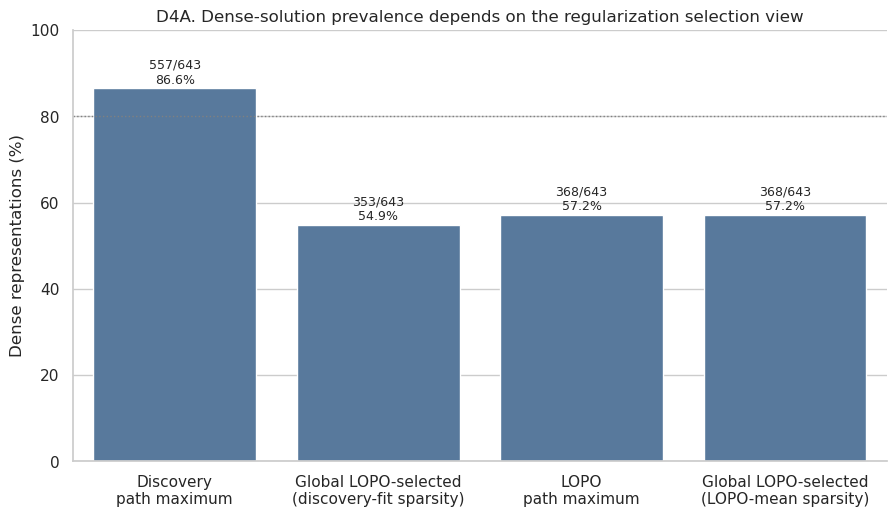

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D4B_lopo_sparsity_vs_transfer_floor.png


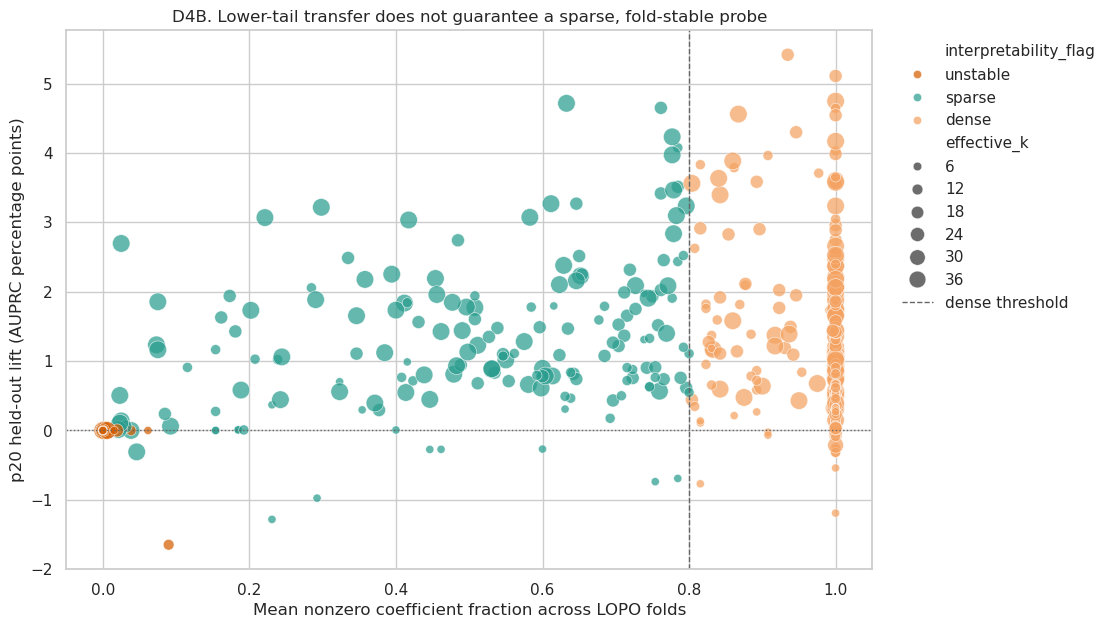

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D4C_near_best_sparse_tradeoff.png


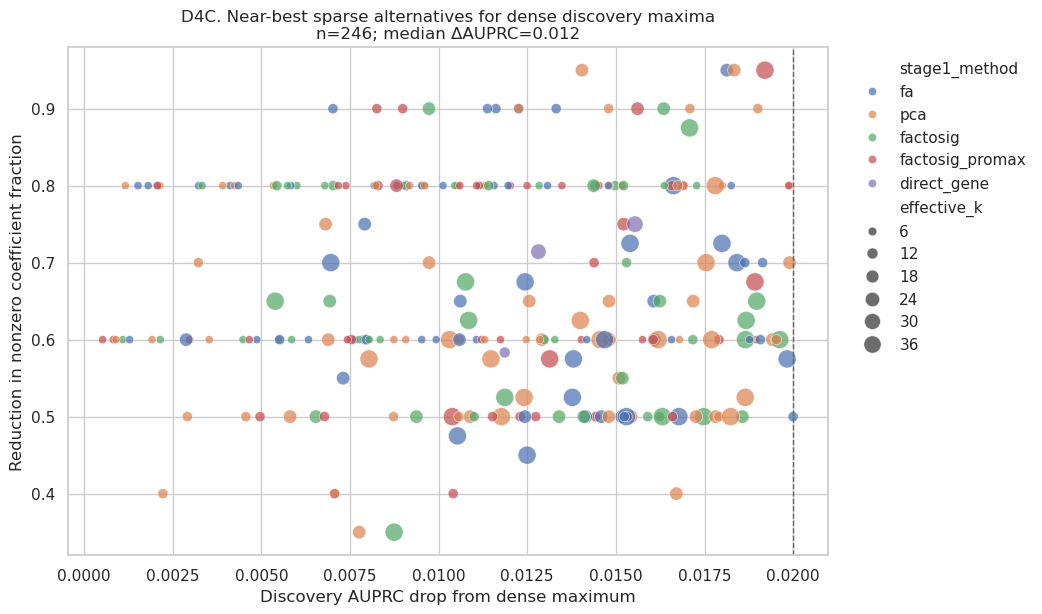

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D4D_panel_interpretability_composition.png


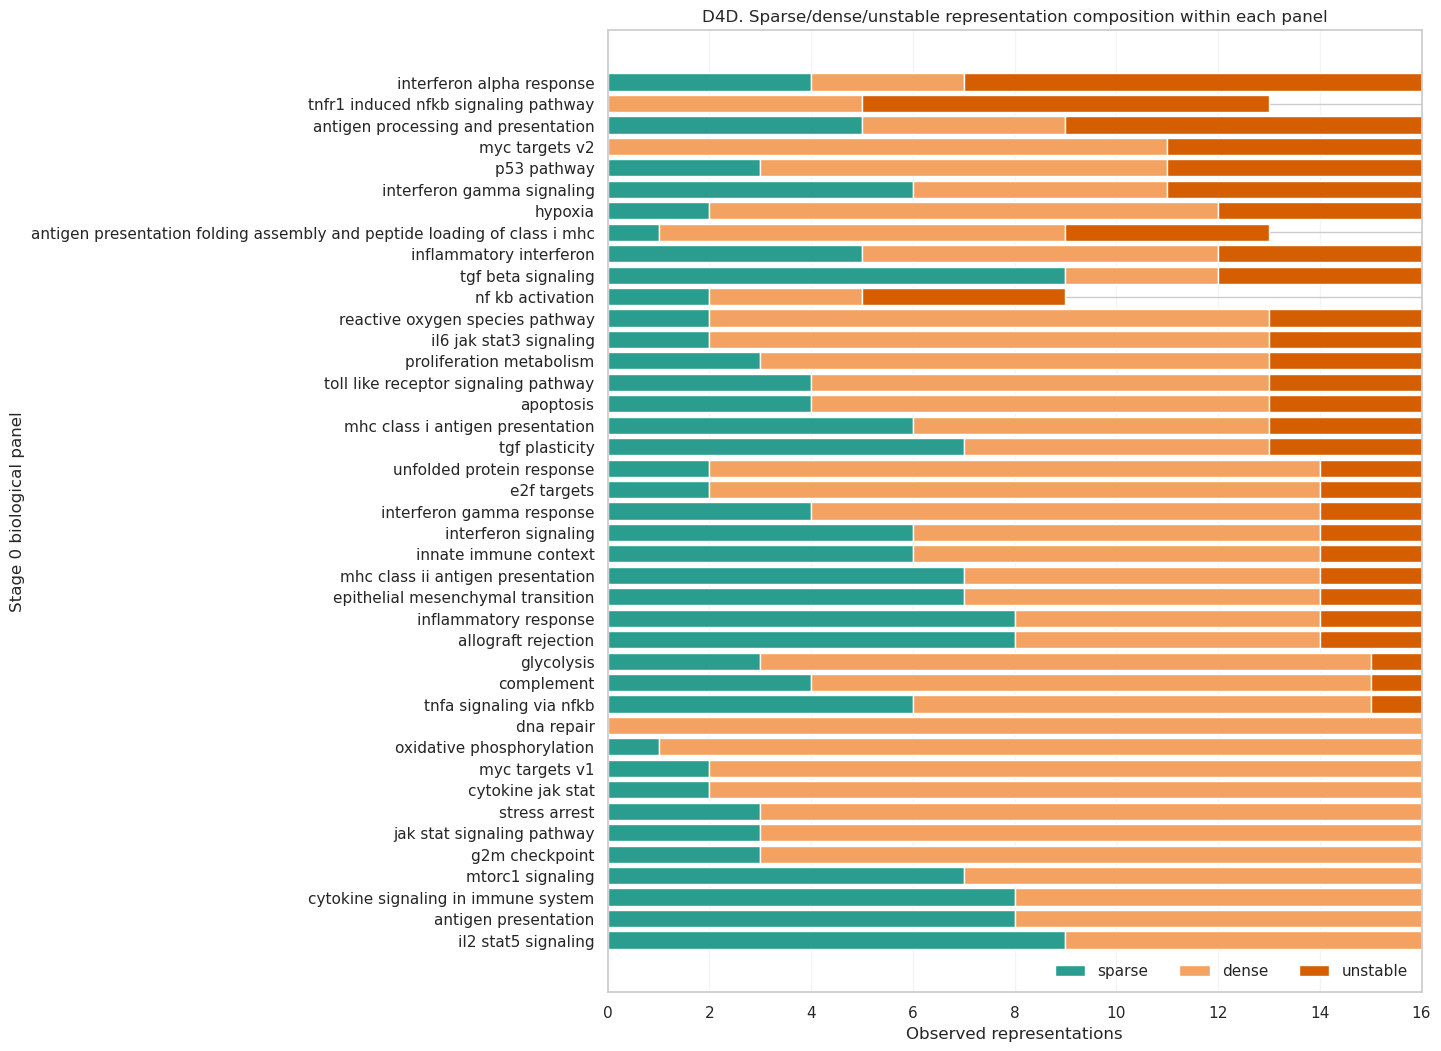

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D4E_L5-01-primary_stress_arrest.png


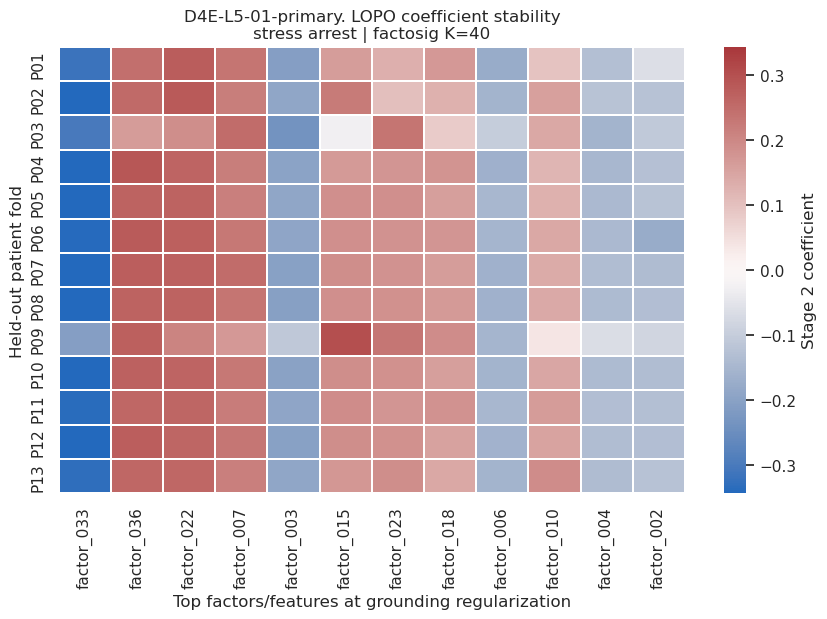

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D4E_L5-02-primary_inflammatory_response.png


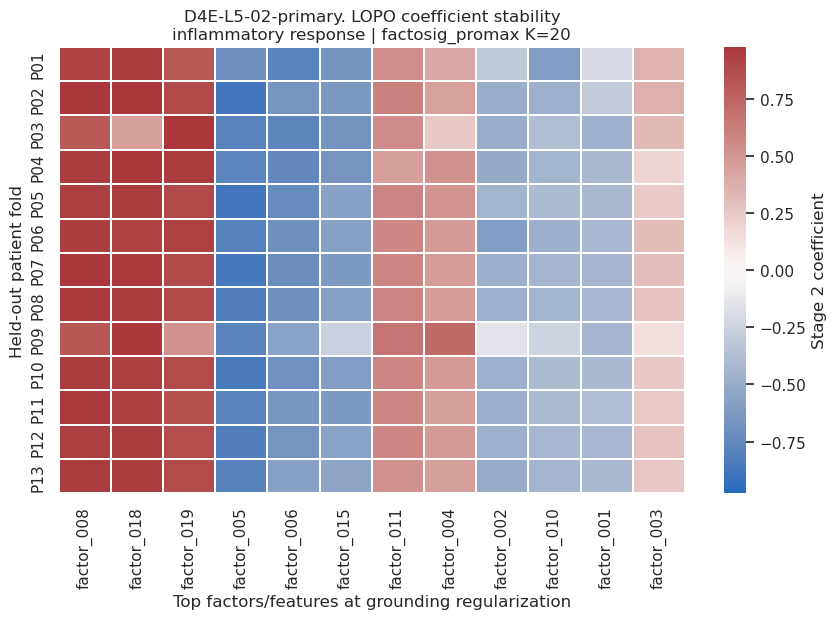

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D4E_L5-03-primary_allograft_rejection.png


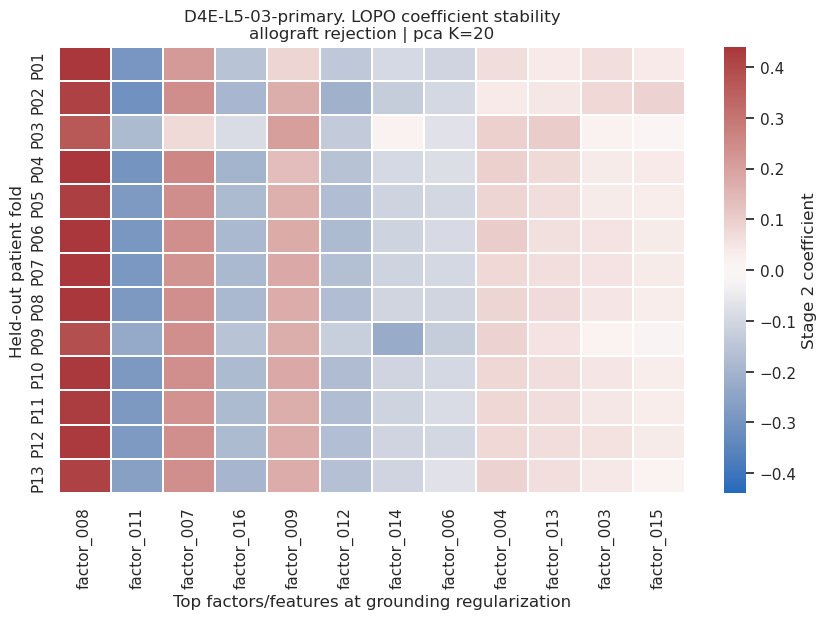

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D4E_L5-04-primary_cytokine_jak_stat.png


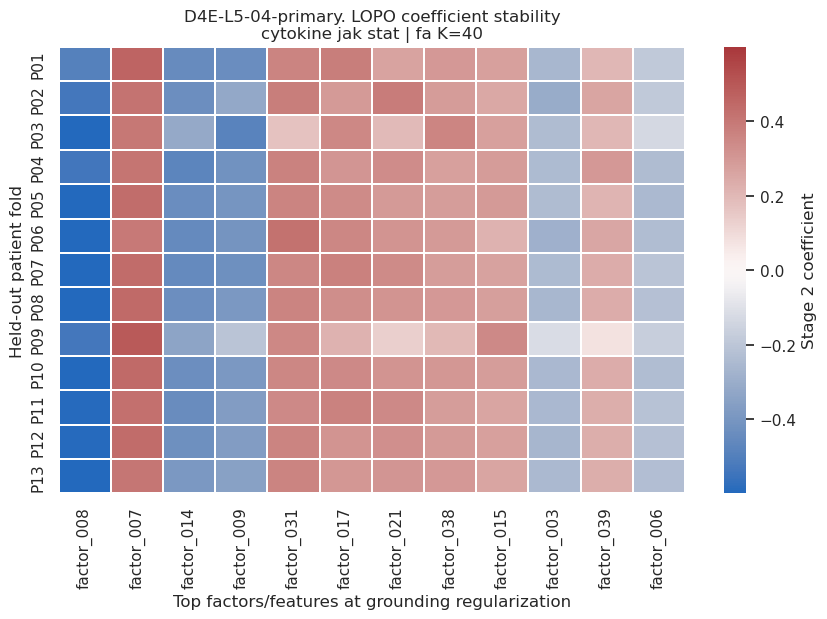

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D4E_L5-05-primary_il2_stat5_signaling.png


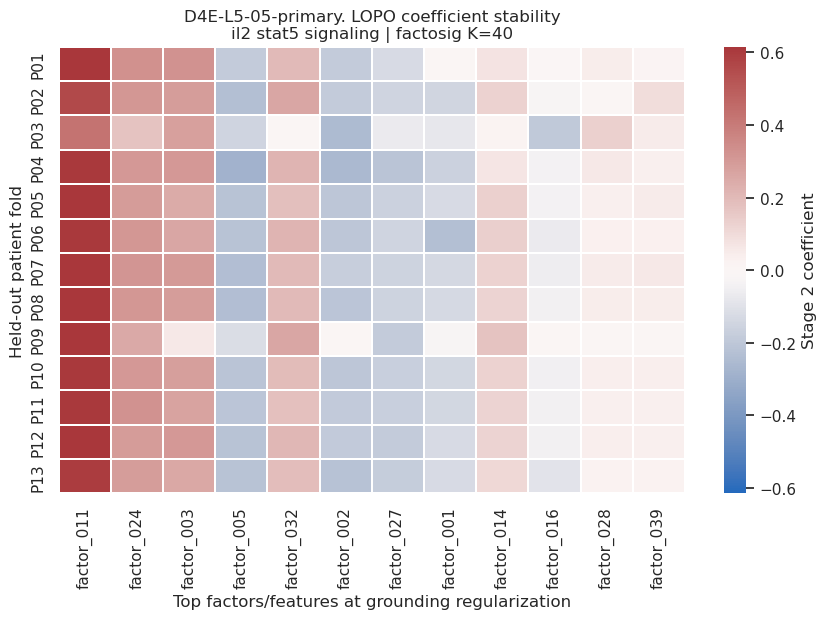

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D4E_L5-06-primary_interferon_signaling.png


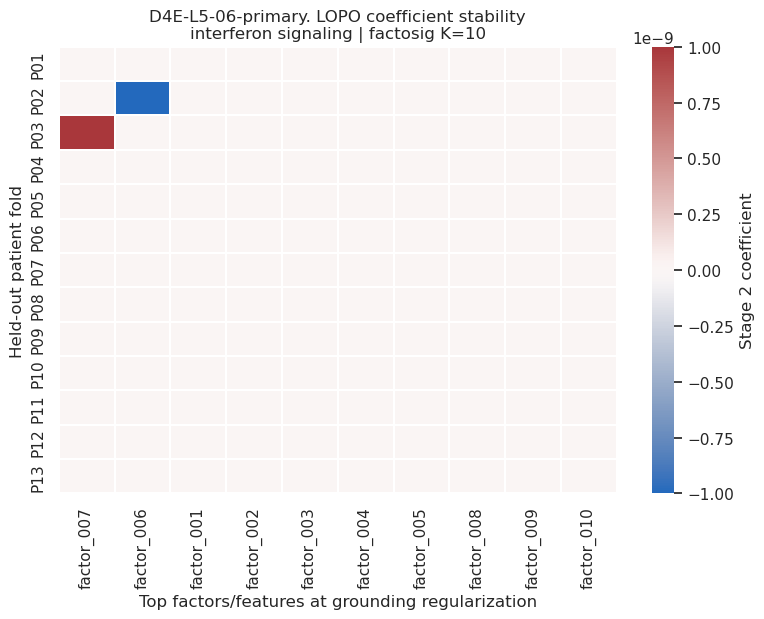

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D4E_L5-07-primary_hypoxia.png


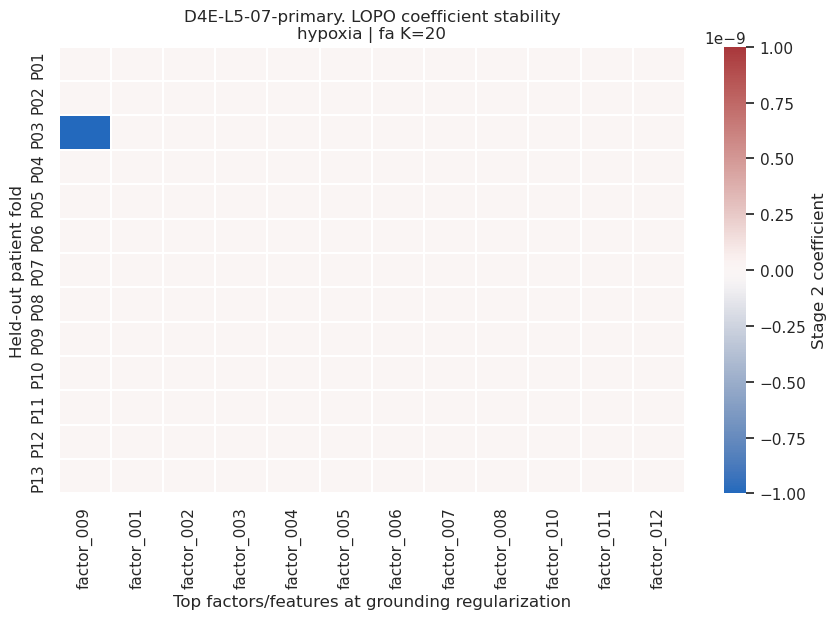

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D4E_L5-08-primary_interferon_gamma_signaling.png


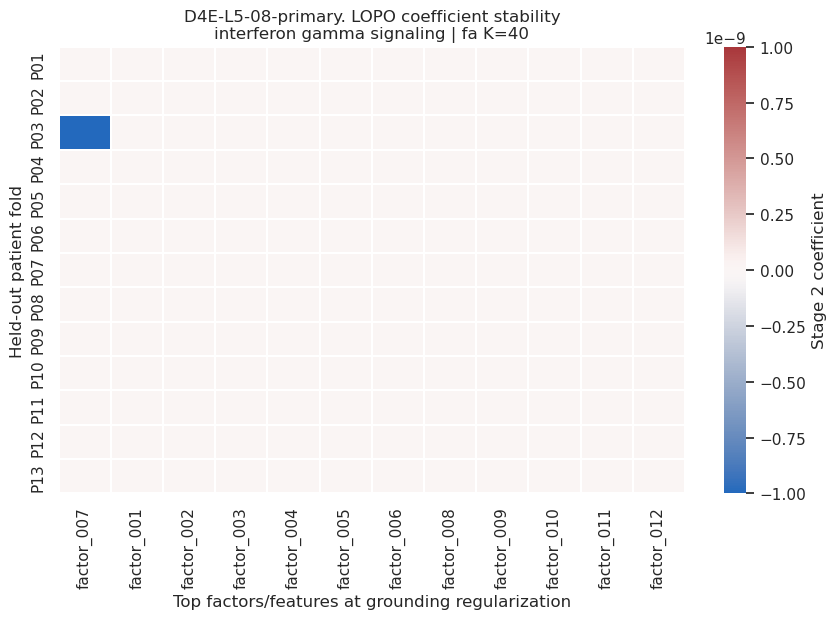

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D4E_L5-09-primary_unfolded_protein_response.png


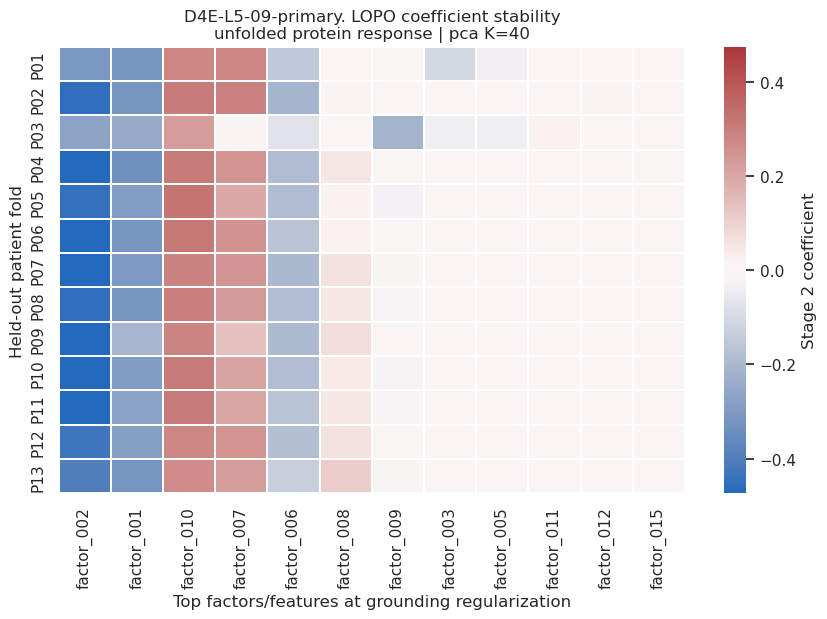

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D4E_L5-10-primary_tgf_beta_signaling.png


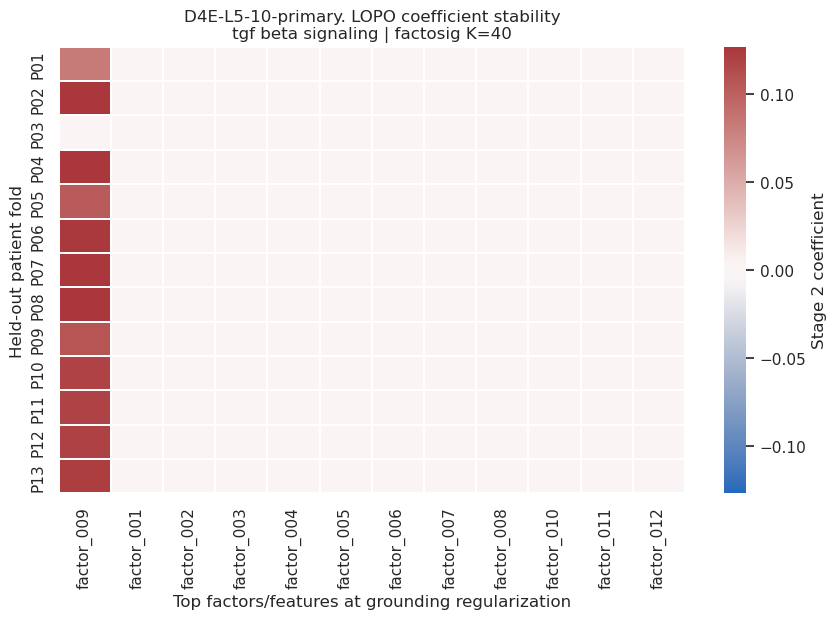

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D4E_L5-11-primary_antigen_processing_and_presentation.png


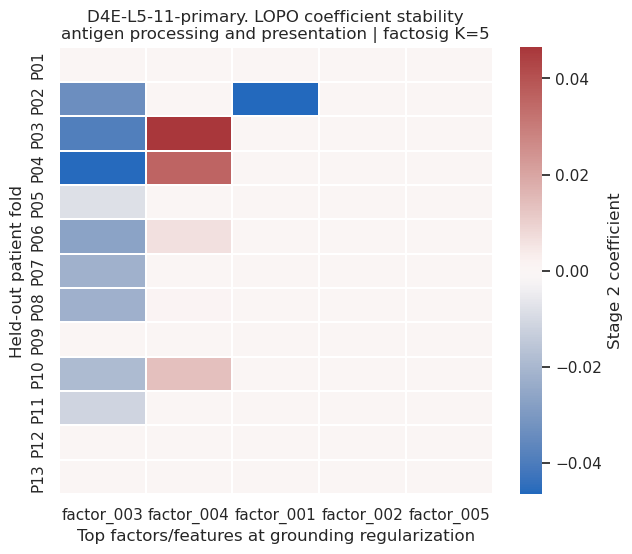

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D4E_L5-12-primary_proliferation_metabolism.png


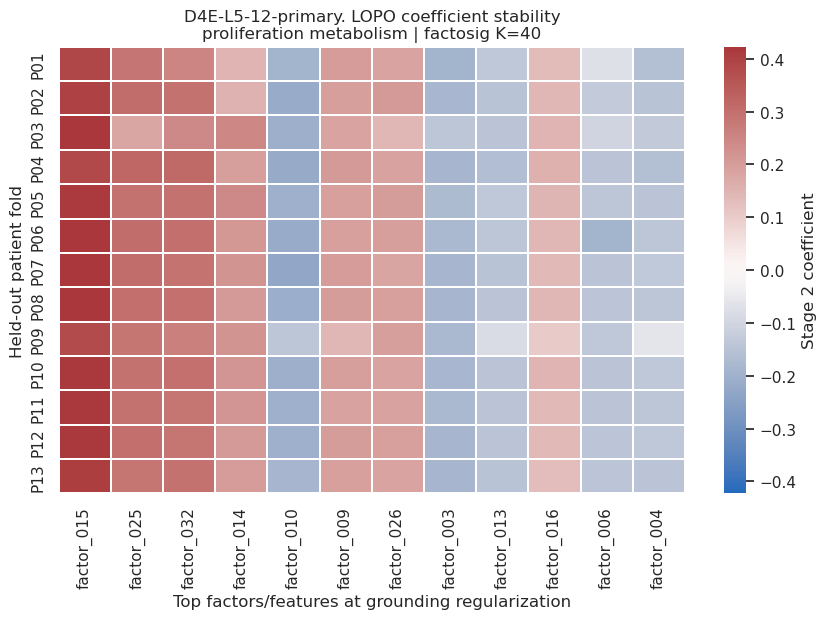

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D4E_L5-13-direct-gene_nf_kb_activation.png


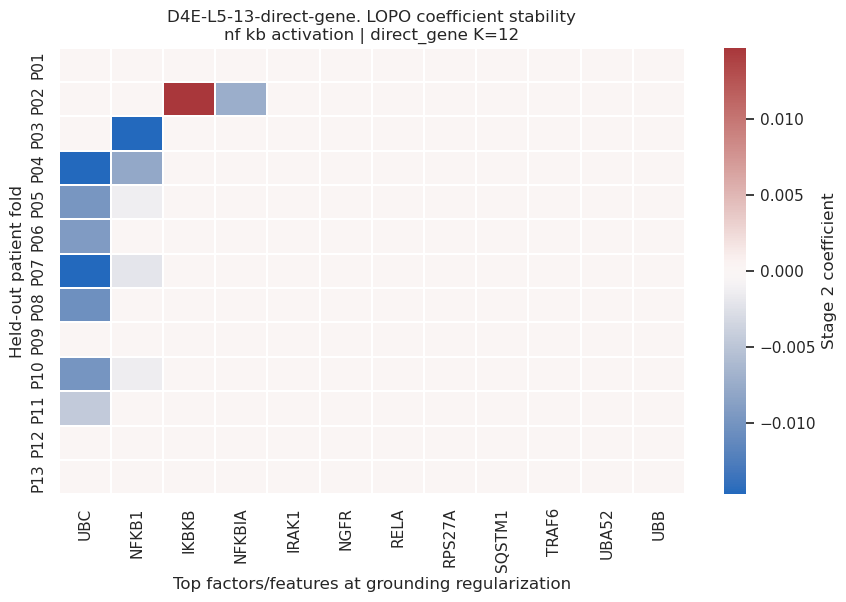

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D4E_L5-13-primary_nf_kb_activation.png


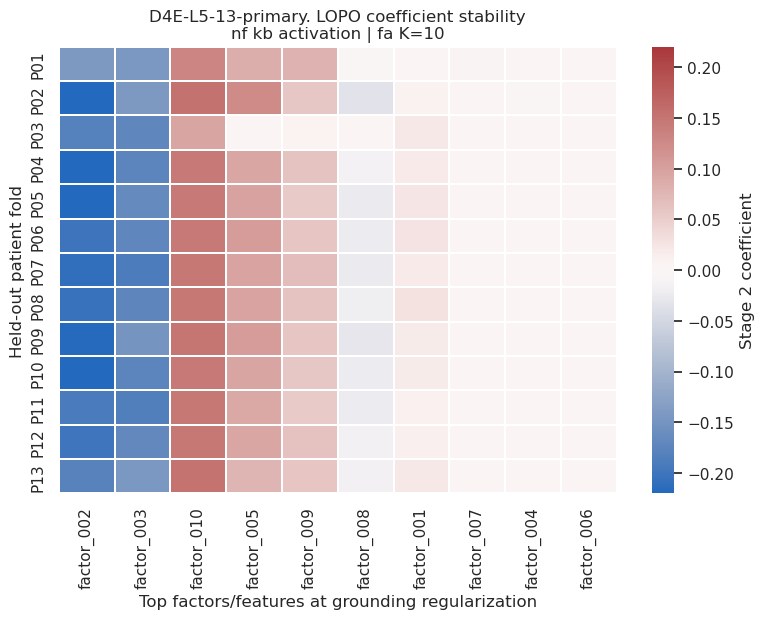

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D4E_L5-14-primary_p53_pathway.png


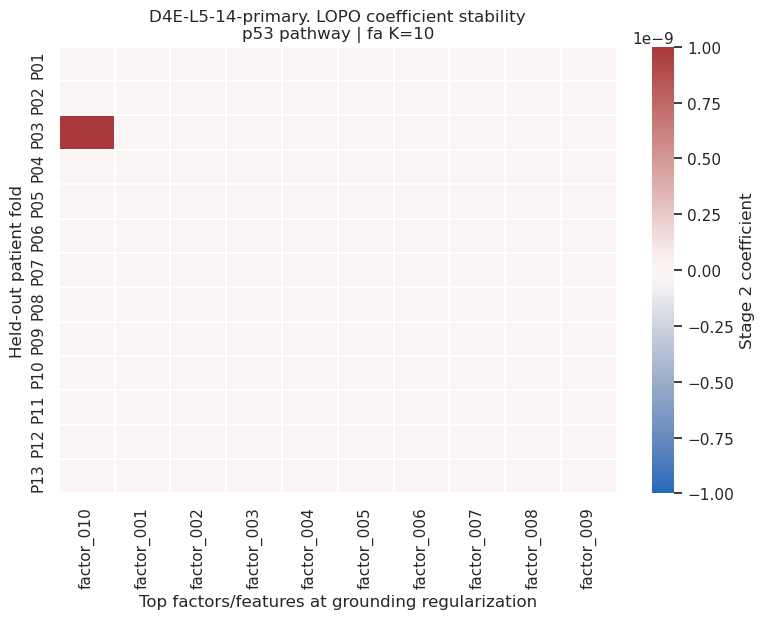

Generated 15 D4E LOPO stability heatmaps.


In [5]:
# D4A — prevalence of dense solutions under four selection views.
fig, ax = plt.subplots(figsize=(10.5, 5.6))
d4a = path_audit_summary.copy()
d4a["percent_dense"] = 100 * d4a["fraction_dense"]
d4a["plot_label"] = [
    "Discovery\npath maximum",
    "Global LOPO-selected\n(discovery-fit sparsity)",
    "LOPO\npath maximum",
    "Global LOPO-selected\n(LOPO-mean sparsity)",
]
sns.barplot(data=d4a, x="plot_label", y="percent_dense", color="#4C78A8", ax=ax)
for patch, value, count in zip(ax.patches, d4a["percent_dense"], d4a["dense_representations"]):
    ax.text(patch.get_x() + patch.get_width() / 2, value + 1.0, f"{count}/643\n{value:.1f}%", ha="center", fontsize=9)
ax.axhline(80, color="0.5", lw=1, ls=":")
ax.set_ylim(0, max(100, float(d4a["percent_dense"].max()) + 12))
ax.set_xlabel("")
ax.set_ylabel("Dense representations (%)")
ax.set_title("D4A. Dense-solution prevalence depends on the regularization selection view")
ax.tick_params(axis="x", rotation=0)
sns.despine(ax=ax)
d4a_png = save_figure(fig, "D4A_dense_solution_prevalence")
plt.show()

# D4B — selected LOPO sparsity versus lower-tail transfer.
fig, ax = plt.subplots(figsize=(10.4, 7.0))
palette = {"sparse": "#2A9D8F", "dense": "#F4A261", "unstable": "#D55E00"}
sns.scatterplot(
    data=representation_interpretability,
    x="selected_lopo_nonzero_fraction",
    y=100 * representation_interpretability["patient_p20_lift"],
    hue="interpretability_flag",
    palette=palette,
    size="effective_k",
    sizes=(35, 160),
    alpha=0.72,
    ax=ax,
)
ax.axvline(DENSE_THRESHOLD, color="0.4", ls="--", lw=1, label="dense threshold")
ax.axhline(0, color="0.4", ls=":", lw=1)
ax.set_xlabel("Mean nonzero coefficient fraction across LOPO folds")
ax.set_ylabel("p20 held-out lift (AUPRC percentage points)")
ax.set_title("D4B. Lower-tail transfer does not guarantee a sparse, fold-stable probe")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=False)
d4b_png = save_figure(fig, "D4B_lopo_sparsity_vs_transfer_floor")
plt.show()

# D4C — near-best sparse trade-off for dense discovery maxima.
d4c = representation_interpretability.loc[
    representation_interpretability["discovery_path_best_is_dense"]
    & representation_interpretability["discovery_near_best_sparse_available"]
].copy()
d4c["nonzero_fraction_reduction"] = (
    d4c["discovery_path_best_nonzero_fraction"]
    - d4c["discovery_near_best_sparse_nonzero_fraction"]
)
fig, ax = plt.subplots(figsize=(9.8, 6.6))
sns.scatterplot(
    data=d4c,
    x="discovery_near_best_sparse_auprc_drop",
    y="nonzero_fraction_reduction",
    hue="stage1_method",
    size="effective_k",
    sizes=(35, 170),
    alpha=0.72,
    ax=ax,
)
ax.axvline(NEAR_BEST_TOLERANCE, color="0.4", ls="--", lw=1)
ax.set_xlabel("Discovery AUPRC drop from dense maximum")
ax.set_ylabel("Reduction in nonzero coefficient fraction")
ax.set_title(
    "D4C. Near-best sparse alternatives for dense discovery maxima\n"
    f"n={len(d4c)}; median ΔAUPRC={d4c['discovery_near_best_sparse_auprc_drop'].median():.3f}"
)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=False)
d4c_png = save_figure(fig, "D4C_near_best_sparse_tradeoff")
plt.show()

# D4D — composition of representation flags within each panel.
d4d = (
    representation_interpretability.groupby(["short_panel_label", "interpretability_flag"]).size()
    .unstack(fill_value=0)
    .reindex(columns=["sparse", "dense", "unstable"], fill_value=0)
)
d4d["sort_unstable"] = d4d["unstable"]
d4d["sort_dense"] = d4d["dense"]
d4d = d4d.sort_values(["sort_unstable", "sort_dense"], ascending=[True, True]).drop(columns=["sort_unstable", "sort_dense"])
fig, ax = plt.subplots(figsize=(10.5, 12.5))
left = np.zeros(len(d4d))
for flag in ["sparse", "dense", "unstable"]:
    ax.barh(d4d.index, d4d[flag], left=left, color=palette[flag], label=flag)
    left += d4d[flag].to_numpy()
ax.set_xlabel("Observed representations")
ax.set_ylabel("Stage 0 biological panel")
ax.set_title("D4D. Sparse/dense/unstable representation composition within each panel")
ax.legend(frameon=False, ncol=3, loc="lower right")
ax.grid(axis="x", alpha=0.2)
d4d_png = save_figure(fig, "D4D_panel_interpretability_composition")
plt.show()

grounding_coefficients = selected_lopo_coefficients.loc[
    selected_lopo_coefficients["grounding_target_ids"].fillna("").ne("")
].copy()
grounding_coefficients["grounding_target_id"] = grounding_coefficients["grounding_target_ids"].str.split(";")
grounding_coefficients = grounding_coefficients.explode("grounding_target_id")
grounding_coefficients = grounding_coefficients.loc[grounding_coefficients["grounding_target_id"].ne("")].copy()

layer5_lopo_feature_records: list[pd.DataFrame] = []
GROUNDING_COEFFICIENT_MATRICES: dict[str, pd.DataFrame] = {}
d4e_pngs: list[Path] = []
for target_id, group in grounding_coefficients.groupby("grounding_target_id", sort=True):
    matrix = group.pivot_table(
        index="heldout_patient",
        columns="feature_id",
        values="coefficient",
        aggfunc="mean",
    ).fillna(0.0)
    GROUNDING_COEFFICIENT_MATRICES[target_id] = matrix
    nonzero = matrix.abs().gt(1e-12)
    signs = np.sign(matrix.where(nonzero))
    feature_summary = pd.DataFrame(
        {
            "grounding_target_id": target_id,
            "feature_id": matrix.columns.astype(str),
            "selection_frequency": nonzero.mean(axis=0).to_numpy(),
            "sign_stability": signs.mean(axis=0, skipna=True).abs().fillna(0).to_numpy(),
            "mean_abs_coefficient": matrix.abs().mean(axis=0).to_numpy(),
            "mean_coefficient": matrix.mean(axis=0).to_numpy(),
            "n_folds_selected": nonzero.sum(axis=0).to_numpy(),
            "n_folds_total": matrix.shape[0],
        }
    ).sort_values(
        ["selection_frequency", "sign_stability", "mean_abs_coefficient"],
        ascending=[False, False, False],
    )
    feature_summary["fold_stable_feature"] = (
        feature_summary["selection_frequency"].ge(STABLE_SELECTION_FREQUENCY)
        & feature_summary["sign_stability"].ge(STABLE_SIGN_THRESHOLD)
    )
    feature_summary["feature_rank"] = np.arange(1, len(feature_summary) + 1)
    layer5_lopo_feature_records.append(feature_summary)

    top_features = feature_summary.nlargest(min(12, len(feature_summary)), "mean_abs_coefficient")["feature_id"]
    heatmap = matrix.reindex(columns=top_features)
    vmax = max(float(np.nanpercentile(np.abs(heatmap.to_numpy()), 98)), 1e-9)
    target_context = layer5_targets.loc[layer5_targets["grounding_target_id"].eq(target_id)].iloc[0]
    fig, ax = plt.subplots(figsize=(max(7.0, 0.55 * len(top_features) + 3.5), 5.8))
    sns.heatmap(
        heatmap,
        cmap="vlag",
        center=0,
        vmin=-vmax,
        vmax=vmax,
        linewidths=0.25,
        linecolor="white",
        cbar_kws={"label": "Stage 2 coefficient"},
        ax=ax,
    )
    ax.set_xlabel("Top factors/features at grounding regularization")
    ax.set_ylabel("Held-out patient fold")
    ax.set_title(
        f"D4E-{target_id}. LOPO coefficient stability\n"
        f"{target_context['short_panel_label']} | {target_context['stage1_method']} K={int(target_context['effective_k'])}"
    )
    stem = re.sub(r"[^A-Za-z0-9_-]+", "_", f"D4E_{target_id}_{target_context['short_panel_label']}")
    d4e_pngs.append(save_figure(fig, stem))
    plt.show()

layer5_lopo_feature_stability = pd.concat(layer5_lopo_feature_records, ignore_index=True).merge(
    layer5_targets[
        [
            "grounding_target_id",
            "stage0_panel_id",
            "short_panel_label",
            "representation_id",
            "grounding_role",
            "grounding_regularization_source",
            "provisional_three_way_taxonomy",
            "method_stability_label",
        ]
    ],
    on="grounding_target_id",
    how="left",
    validate="many_to_one",
)
layer5_lopo_feature_path = write_csv(
    layer5_lopo_feature_stability,
    "layer5_grounding_lopo_feature_stability.csv",
)
print(f"Generated {len(d4e_pngs)} D4E LOPO stability heatmaps.")

## 5. Layer 5 — factor→gene grounding across biological strata

- **Question:** Does a prior panel act as one axis, or decompose into recurrent factors with distinct genes and patient usage?
- **Sampling:** 14 panels cover every provisional taxonomy class, all observed DR stability classes, multiple biological themes, brittle/null comparators, and both patient-only panels. A fifteenth target is an NF-κB direct-gene sensitivity.
- **Grounding row:** retain the pooled-LOPO-selected representation; when its selected Stage 2 row is dense and a sparse LOPO row is within ΔAUPRC ≤ 0.02, use that near-best sparse regularization for grounding.
- **Patient comparison:** patient-specific feature sets use each patient's apparent best row and are explicitly marked as in-sample. Dense L2 feature-set overlaps are flagged as weakly informative.

In [6]:
selected_discovery_coefficients = extract_requested_coefficients(
    SOURCE_PATHS["discovery_coefficients"],
    wanted_coefficients,
    usecols=DISCOVERY_COEFFICIENT_COLUMNS,
    cache_stem="selected_discovery_coefficients",
)
selected_discovery_coefficients["coefficient"] = pd.to_numeric(
    selected_discovery_coefficients["coefficient"], errors="coerce"
).fillna(0.0)
selected_discovery_coefficients["is_nonzero_bool"] = (
    selected_discovery_coefficients["is_nonzero"].astype(str).str.lower().isin(["true", "1"])
    | selected_discovery_coefficients["coefficient"].abs().gt(1e-12)
)
discovery_grounding_coefficients = selected_discovery_coefficients.loc[
    selected_discovery_coefficients["grounding_target_ids"].fillna("").ne("")
].copy()
discovery_grounding_coefficients["grounding_target_id"] = discovery_grounding_coefficients[
    "grounding_target_ids"
].str.split(";")
discovery_grounding_coefficients = discovery_grounding_coefficients.explode("grounding_target_id")
discovery_grounding_coefficients = discovery_grounding_coefficients.loc[
    discovery_grounding_coefficients["grounding_target_id"].ne("")
].copy()
assert discovery_grounding_coefficients["grounding_target_id"].nunique() == 15

PATIENT_SCORECARD_COLUMNS = [
    "stage0_panel_id",
    "representation_family",
    "stage1_method",
    "effective_k",
    "seed",
    "patient",
    "penalty",
    "C",
    "l1_ratio",
    "stage2_auprc",
    "stage2_auroc",
    "nonzero_coefficient_count",
    "selected_feature_ids",
    "status",
    "evaluation_fit_scope",
]
patient_scorecard = pd.read_csv(
    SOURCE_PATHS["patient_specific_scorecard"],
    usecols=PATIENT_SCORECARD_COLUMNS,
    low_memory=False,
)
patient_scorecard = add_regularization_keys(add_identity_columns(patient_scorecard))
target_representation_ids = set(layer5_targets["representation_id"])
patient_scorecard = patient_scorecard.loc[
    patient_scorecard["status"].eq("ok")
    & patient_scorecard["representation_id"].isin(target_representation_ids)
].copy()
patient_scorecard["patient_id"] = patient_scorecard["patient"].astype(str)


def choose_patient_apparent_rows(frame: pd.DataFrame) -> pd.DataFrame:
    selected_rows = []
    for _, group in frame.groupby(["representation_id", "patient_id"], sort=True):
        eligible = group.loc[pd.to_numeric(group["nonzero_coefficient_count"], errors="coerce").fillna(0).ge(1)].copy()
        if eligible.empty:
            eligible = group.copy()
        eligible["penalty_rank"] = eligible["penalty_key"].map(PENALTY_RANK).fillna(99)
        selected_rows.append(
            eligible.sort_values(
                ["stage2_auprc", "stage2_auroc", "nonzero_coefficient_count", "penalty_rank", "C_log10_key"],
                ascending=[False, False, True, True, True],
            ).iloc[0]
        )
    return pd.DataFrame(selected_rows).reset_index(drop=True)


patient_selected = choose_patient_apparent_rows(patient_scorecard)
assert patient_selected["representation_id"].nunique() == 15
assert patient_selected["patient_id"].nunique() == 9
assert patient_selected["evaluation_fit_scope"].eq("apparent_within_patient").all()

stage1_paths = stage0_index[
    [
        "representation_id",
        "loadings_path",
        "features_path",
        "stage1_metadata_path",
        "gene_list_path",
    ]
].drop_duplicates("representation_id")
layer5_targets = layer5_targets.merge(
    stage1_paths,
    on="representation_id",
    how="left",
    validate="many_to_one",
)
assert layer5_targets["stage1_metadata_path"].notna().all()

factor_records: list[dict[str, object]] = []
gene_records: list[dict[str, object]] = []
patient_overlap_records: list[dict[str, object]] = []

for target in layer5_targets.sort_values(["sample_order", "grounding_role"]).itertuples(index=False):
    target_id = target.grounding_target_id
    lopo_features = layer5_lopo_feature_stability.loc[
        layer5_lopo_feature_stability["grounding_target_id"].eq(target_id)
    ].copy()
    stable = lopo_features.loc[lopo_features["fold_stable_feature"]].sort_values(
        ["selection_frequency", "sign_stability", "mean_abs_coefficient"],
        ascending=[False, False, False],
    )
    ordered = pd.concat(
        [
            stable,
            lopo_features.loc[~lopo_features["feature_id"].isin(stable["feature_id"])].sort_values(
                ["mean_abs_coefficient", "selection_frequency", "sign_stability"],
                ascending=[False, False, False],
            ),
        ],
        ignore_index=True,
    ).drop_duplicates("feature_id")
    selected_factors = ordered.head(min(TOP_FACTORS_PER_TARGET, len(ordered))).copy()
    if selected_factors.empty:
        raise AssertionError(f"No LOPO factors available for {target_id}")

    discovery_sub = discovery_grounding_coefficients.loc[
        discovery_grounding_coefficients["grounding_target_id"].eq(target_id)
    ].copy()
    discovery_by_feature = discovery_sub.groupby("feature_id", as_index=True)["coefficient"].mean()
    patient_sub = patient_selected.loc[
        patient_selected["representation_id"].eq(target.representation_id)
    ].copy()
    patient_sets = {
        row.patient_id: parse_feature_set(row.selected_feature_ids)
        for row in patient_sub.itertuples(index=False)
    }
    patient_selection_frequency = pd.Series(
        {
            feature_id: np.mean([feature_id in feature_set for feature_set in patient_sets.values()])
            for feature_id in lopo_features["feature_id"]
        }
    )

    loadings_path = resolve_experiment_path(target.loadings_path)
    metadata_path = resolve_experiment_path(target.stage1_metadata_path)
    gene_list_path = resolve_experiment_path(target.gene_list_path)
    metadata = json.loads(metadata_path.read_text()) if metadata_path is not None else {}
    gene_payload = json.loads(gene_list_path.read_text()) if gene_list_path is not None else {}
    genes = list(gene_payload.get("genes", []))

    if target.representation_family == "direct_gene":
        loadings = None
    else:
        if loadings_path is None or not loadings_path.exists():
            raise FileNotFoundError(f"Missing loadings for {target_id}: {loadings_path}")
        loadings = np.load(loadings_path)
        if loadings.ndim != 2:
            raise AssertionError(f"Loadings must be 2D for {target_id}: {loadings.shape}")
        if loadings.shape[0] != len(genes) and loadings.shape[1] == len(genes):
            loadings = loadings.T
        assert loadings.shape[0] == len(genes) == int(metadata["n_genes"])
        assert loadings.shape[1] == int(target.effective_k)

    for factor_rank, factor in enumerate(selected_factors.itertuples(index=False), start=1):
        feature_id = str(factor.feature_id)
        discovery_coefficient = float(discovery_by_feature.get(feature_id, np.nan))
        patient_frequency = float(patient_selection_frequency.get(feature_id, 0.0))
        factor_record = {
            "grounding_target_id": target_id,
            "sample_order": int(target.sample_order),
            "stage0_panel_id": target.stage0_panel_id,
            "short_panel_label": target.short_panel_label,
            "biological_theme": target.biological_theme,
            "provisional_three_way_taxonomy": target.provisional_three_way_taxonomy,
            "method_stability_label": target.method_stability_label,
            "grounding_role": target.grounding_role,
            "representation_id": target.representation_id,
            "representation_family": target.representation_family,
            "stage1_method": target.stage1_method,
            "effective_k": int(target.effective_k),
            "grounding_regularization_source": target.grounding_regularization_source,
            "grounding_penalty": target.grounding_penalty,
            "grounding_C": float(target.grounding_C),
            "grounding_l1_ratio": target.grounding_l1_ratio,
            "layer4_interpretability_flag": target.interpretability_flag,
            "feature_id": feature_id,
            "factor_rank_for_grounding": factor_rank,
            "lopo_selection_frequency": float(factor.selection_frequency),
            "lopo_sign_stability": float(factor.sign_stability),
            "lopo_mean_abs_coefficient": float(factor.mean_abs_coefficient),
            "lopo_mean_coefficient": float(factor.mean_coefficient),
            "lopo_fold_stable_feature": bool(factor.fold_stable_feature),
            "discovery_same_regularization_coefficient": discovery_coefficient,
            "patient_apparent_selection_frequency": patient_frequency,
            "factor_selection_basis": "fold-stable first, then LOPO mean absolute coefficient",
        }

        if target.representation_family == "direct_gene":
            factor_record.update(
                {
                    "loading_entropy_normalized": 0.0,
                    "loading_effective_gene_number": 1.0,
                    "loading_top10_absolute_mass": 1.0,
                    "n_grounded_genes": 1,
                }
            )
            gene_records.append(
                {
                    **factor_record,
                    "loading_direction": "identity_gene",
                    "loading_rank_within_direction": 1,
                    "gene": feature_id,
                    "loading": 1.0,
                    "absolute_loading": 1.0,
                    "signed_gene_contribution": float(factor.mean_coefficient),
                }
            )
        else:
            match = re.fullmatch(r"factor_(\d{3})", feature_id)
            if match is None:
                raise ValueError(f"Cannot map non-factor feature {feature_id} for {target_id}")
            factor_index = int(match.group(1)) - 1
            if not 0 <= factor_index < loadings.shape[1]:
                raise IndexError(f"Factor index out of range for {target_id}: {feature_id}")
            loading_values = loadings[:, factor_index].astype(float)
            absolute = np.abs(loading_values)
            total_absolute = float(absolute.sum())
            probabilities = absolute / total_absolute if total_absolute > 0 else np.zeros_like(absolute)
            nonzero_probabilities = probabilities[probabilities > 0]
            entropy = float(-(nonzero_probabilities * np.log(nonzero_probabilities)).sum()) if len(nonzero_probabilities) else 0.0
            normalized_entropy = entropy / math.log(len(genes)) if len(genes) > 1 else 0.0
            top10_mass = float(np.sort(absolute)[-min(10, len(absolute)):].sum() / total_absolute) if total_absolute > 0 else np.nan
            factor_record.update(
                {
                    "loading_entropy_normalized": normalized_entropy,
                    "loading_effective_gene_number": float(math.exp(entropy)),
                    "loading_top10_absolute_mass": top10_mass,
                    "n_grounded_genes": len(genes),
                }
            )
            positive_indices = np.argsort(loading_values)[::-1][: min(TOP_GENES_PER_DIRECTION, len(genes))]
            negative_indices = np.argsort(loading_values)[: min(TOP_GENES_PER_DIRECTION, len(genes))]
            for direction, indices in [("positive_loading", positive_indices), ("negative_loading", negative_indices)]:
                for loading_rank, gene_index in enumerate(indices, start=1):
                    loading_value = float(loading_values[gene_index])
                    gene_records.append(
                        {
                            **factor_record,
                            "loading_direction": direction,
                            "loading_rank_within_direction": loading_rank,
                            "gene": genes[gene_index],
                            "loading": loading_value,
                            "absolute_loading": abs(loading_value),
                            "signed_gene_contribution": float(factor.mean_coefficient) * loading_value,
                        }
                    )
        factor_records.append(factor_record)

    # Scope-overlap sets; L2 uses top-|coef| features because every coefficient is nonzero.
    if str(target.grounding_penalty).lower() == "l2":
        discovery_set_size = min(10, max(3, int(math.ceil(0.25 * int(target.effective_k)))))
        discovery_set = set(discovery_by_feature.abs().nlargest(discovery_set_size).index.astype(str))
        discovery_selection_rule = f"l2_top_abs_{discovery_set_size}"
    else:
        discovery_set = set(
            discovery_sub.loc[discovery_sub["coefficient"].abs().gt(1e-12), "feature_id"].astype(str)
        )
        discovery_selection_rule = "nonzero_sparse_coefficient"
    lopo_recurrent_set = set(
        lopo_features.loc[lopo_features["fold_stable_feature"], "feature_id"].astype(str)
    )
    if not lopo_recurrent_set:
        lopo_recurrent_set = set(selected_factors["feature_id"].astype(str))
        lopo_recurrent_rule = "fallback_top_grounded_features"
    else:
        lopo_recurrent_rule = "selection_frequency_ge_0p5_and_sign_stability_ge_0p8"

    for patient_row in patient_sub.itertuples(index=False):
        patient_set = parse_feature_set(patient_row.selected_feature_ids)
        patient_nonzero_fraction = float(patient_row.nonzero_coefficient_count) / int(target.effective_k)
        patient_overlap_records.append(
            {
                "grounding_target_id": target_id,
                "stage0_panel_id": target.stage0_panel_id,
                "short_panel_label": target.short_panel_label,
                "representation_id": target.representation_id,
                "provisional_three_way_taxonomy": target.provisional_three_way_taxonomy,
                "patient_id": patient_row.patient_id,
                "patient_specific_evaluation_scope": patient_row.evaluation_fit_scope,
                "patient_specific_penalty": patient_row.penalty,
                "patient_specific_C": patient_row.C,
                "patient_specific_l1_ratio": patient_row.l1_ratio,
                "patient_specific_apparent_auprc": patient_row.stage2_auprc,
                "patient_selected_feature_count": len(patient_set),
                "patient_nonzero_fraction": patient_nonzero_fraction,
                "patient_overlap_informative": bool(
                    str(patient_row.penalty).lower() != "l2" and patient_nonzero_fraction <= DENSE_THRESHOLD
                ),
                "discovery_selection_rule": discovery_selection_rule,
                "discovery_selected_feature_count": len(discovery_set),
                "lopo_recurrent_rule": lopo_recurrent_rule,
                "lopo_recurrent_feature_count": len(lopo_recurrent_set),
                "jaccard_patient_vs_discovery": jaccard(patient_set, discovery_set),
                "jaccard_patient_vs_lopo_recurrent": jaccard(patient_set, lopo_recurrent_set),
                "patient_discovery_overlap_count": len(patient_set & discovery_set),
                "patient_lopo_overlap_count": len(patient_set & lopo_recurrent_set),
            }
        )

panel_selected_factors = pd.DataFrame(factor_records)
panel_top_loading_genes = pd.DataFrame(gene_records)
patient_factor_overlap = pd.DataFrame(patient_overlap_records)
assert panel_selected_factors["grounding_target_id"].nunique() == 15
assert panel_selected_factors.groupby("grounding_target_id").size().between(1, TOP_FACTORS_PER_TARGET).all()
assert panel_top_loading_genes["grounding_target_id"].nunique() == 15
assert patient_factor_overlap["grounding_target_id"].nunique() == 15
assert patient_factor_overlap["patient_specific_evaluation_scope"].eq("apparent_within_patient").all()

panel_selected_factors_path = write_csv(
    panel_selected_factors,
    "panel_selected_factors_summary.csv",
)
panel_top_loading_genes_path = write_csv(
    panel_top_loading_genes,
    "panel_top_loading_genes.csv",
)
patient_factor_overlap_path = write_csv(
    patient_factor_overlap,
    "patient_factor_overlap_vs_discovery.csv",
)
patient_selected_path = write_csv(
    patient_selected,
    "layer5_patient_specific_selected_rows.csv",
)

print("Grounded factors:", len(panel_selected_factors))
print("Factor→gene rows:", len(panel_top_loading_genes))
print("Patient overlap rows:", len(patient_factor_overlap))
display(
    panel_selected_factors[
        [
            "grounding_target_id",
            "short_panel_label",
            "feature_id",
            "lopo_selection_frequency",
            "lopo_sign_stability",
            "loading_effective_gene_number",
            "loading_top10_absolute_mass",
        ]
    ].head(20)
)

Using coefficient cache: /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/cache/stage2_diagnostic/layer4_5/selected_discovery_coefficients.pkl.gz


Grounded factors: 45
Factor→gene rows: 843
Patient overlap rows: 135


,grounding_target_id,short_panel_label,feature_id,lopo_selection_frequency,lopo_sign_stability,loading_effective_gene_number,loading_top10_absolute_mass
0,L5-01-primary,stress arrest,factor_033,1.000000,1.0,449.897109,0.098995
1,L5-01-primary,stress arrest,factor_036,1.000000,1.0,462.631934,0.082514
2,L5-01-primary,stress arrest,factor_022,1.000000,1.0,443.951209,0.097595
3,L5-02-primary,inflammatory response,factor_008,1.000000,1.0,85.457650,0.299434
4,L5-02-primary,inflammatory response,factor_018,1.000000,1.0,89.164751,0.283431
5,L5-02-primary,inflammatory response,factor_019,1.000000,1.0,87.311691,0.304529
6,L5-03-primary,allograft rejection,factor_008,1.000000,1.0,106.381694,0.210581
7,L5-03-primary,allograft rejection,factor_011,1.000000,1.0,111.460557,0.201205
8,L5-03-primary,allograft rejection,factor_007,1.000000,1.0,105.793934,0.210892
9,L5-04-primary,cytokine jak stat,factor_008,1.000000,1.0,498.064983,0.067219


## 6. D5 — factor decomposition and gene grounding

- **D5A:** how many recurrent factors each stratified target contributes.
- **D5B:** per-target Stage 1 loading heatmaps for up to three selected factors, with positive and negative genes computed directly from `loadings.npy`.
- **D5C:** patient-specific apparent factor-set overlap with same-regularization discovery and recurrent LOPO factors.
- **D5D:** loading concentration versus effective gene number; concentrated factors are easier to name, while diffuse factors require caution.

The direct-gene NF-κB sensitivity appears as an identity mapping and should not be interpreted as a latent factor.

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D5A_grounded_factor_depth.png


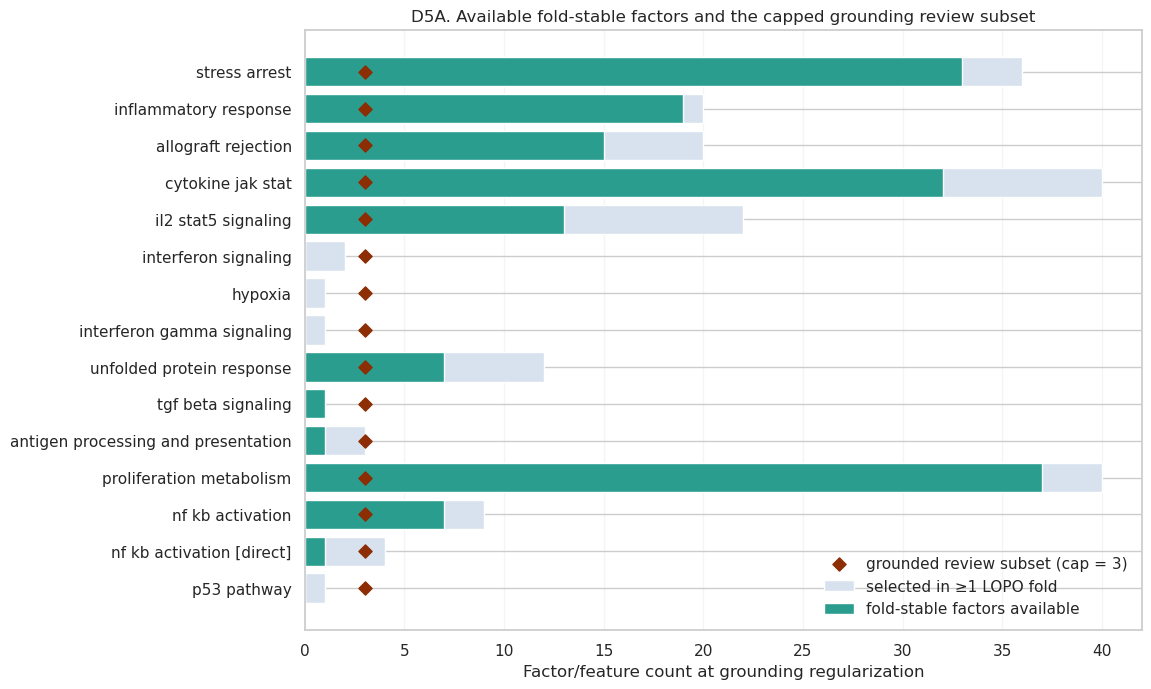

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D5B_L5-01-primary_stress_arrest.png


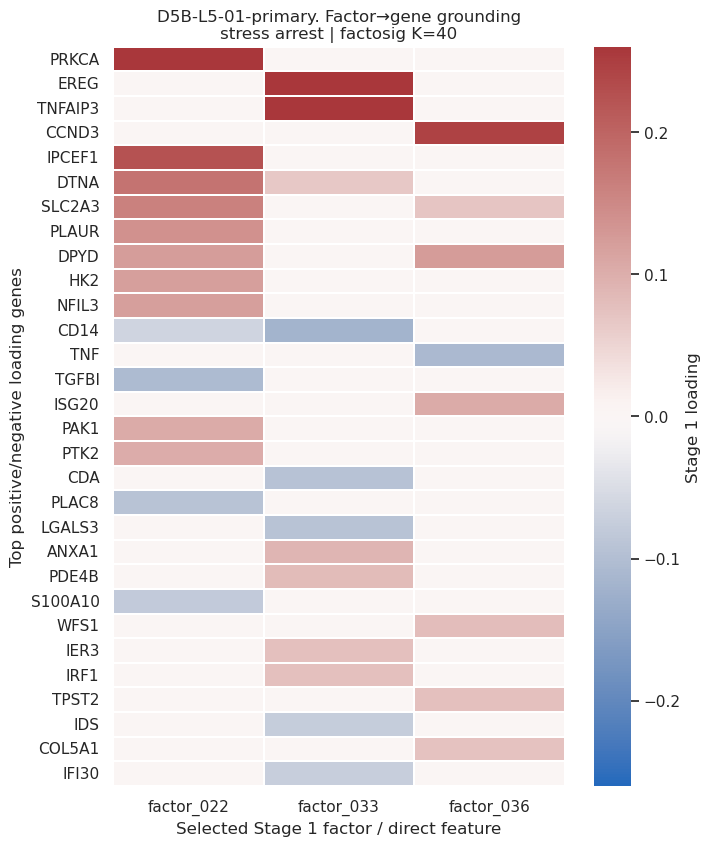

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D5B_L5-02-primary_inflammatory_response.png


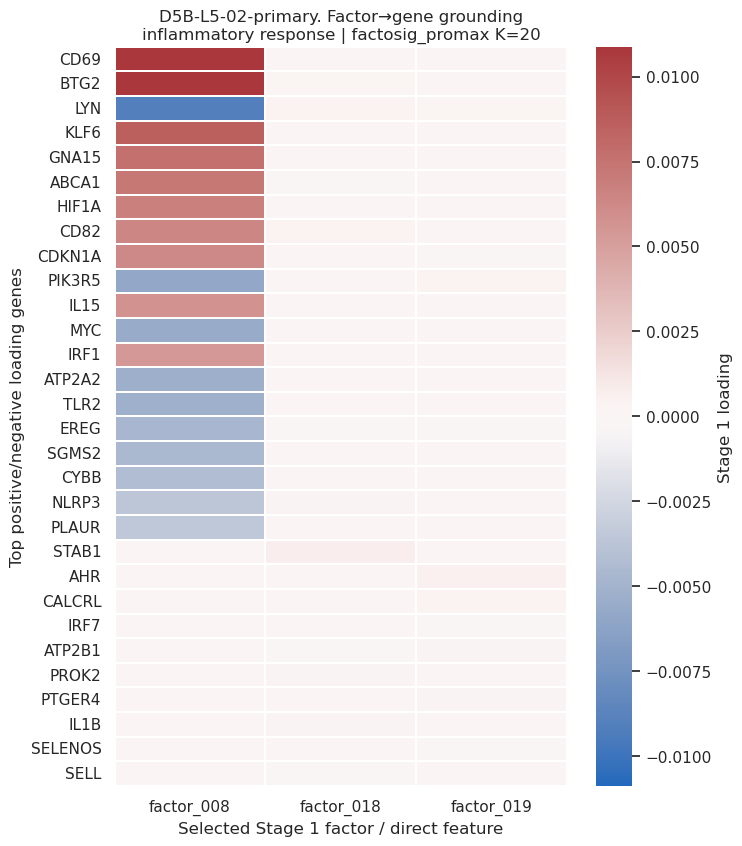

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D5B_L5-03-primary_allograft_rejection.png


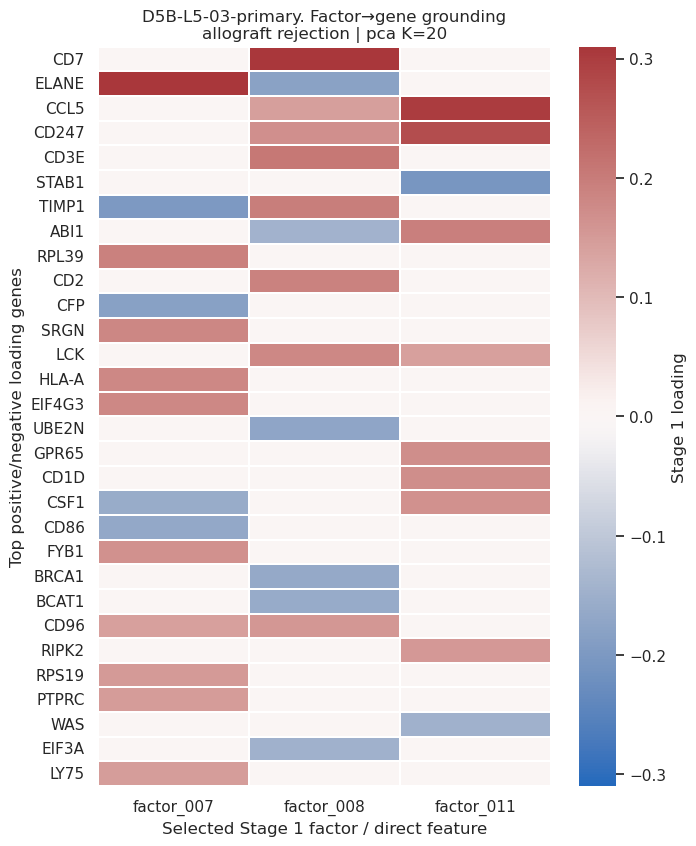

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D5B_L5-04-primary_cytokine_jak_stat.png


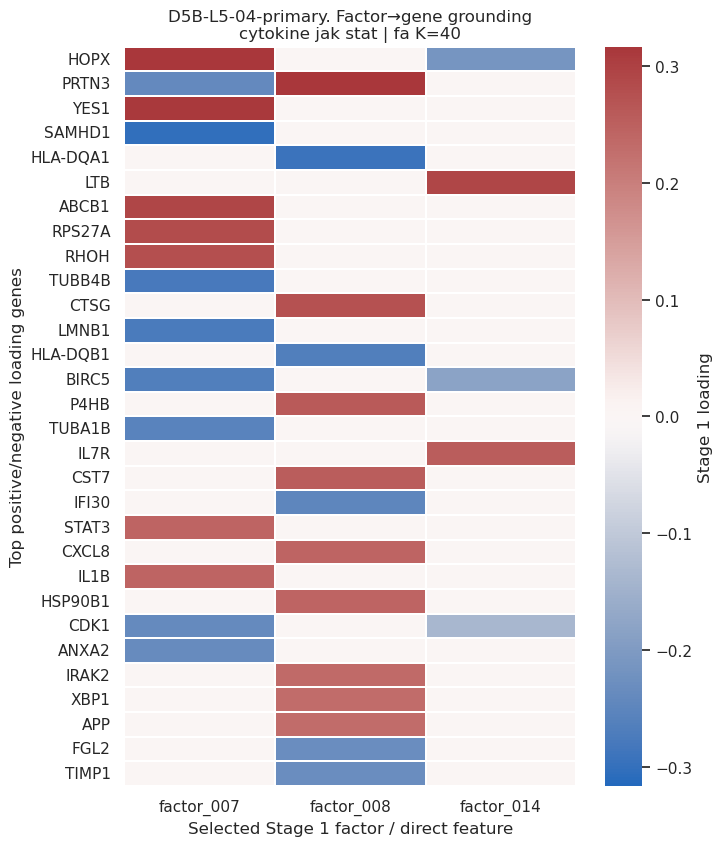

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D5B_L5-05-primary_il2_stat5_signaling.png


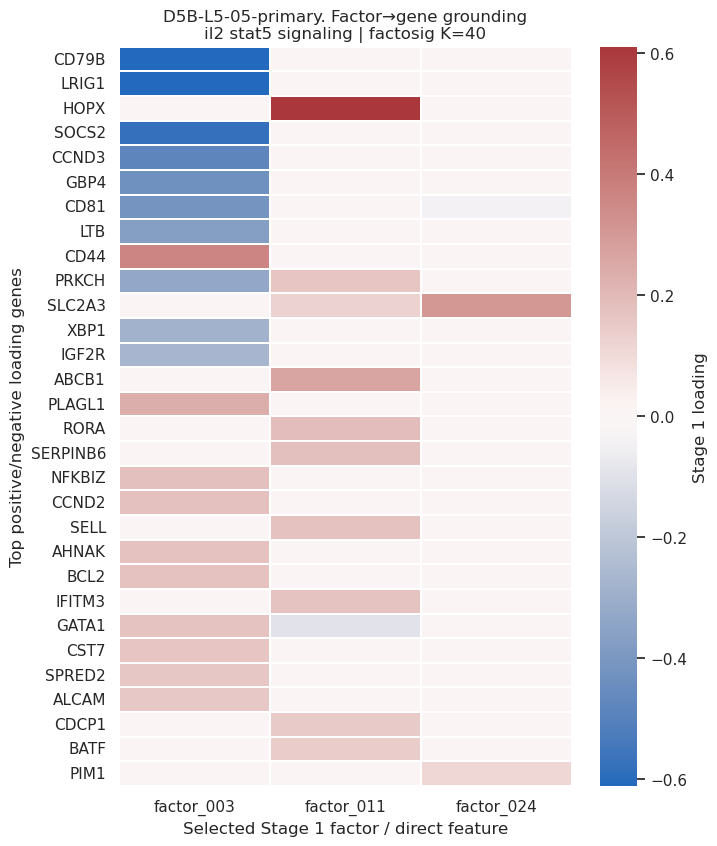

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D5B_L5-06-primary_interferon_signaling.png


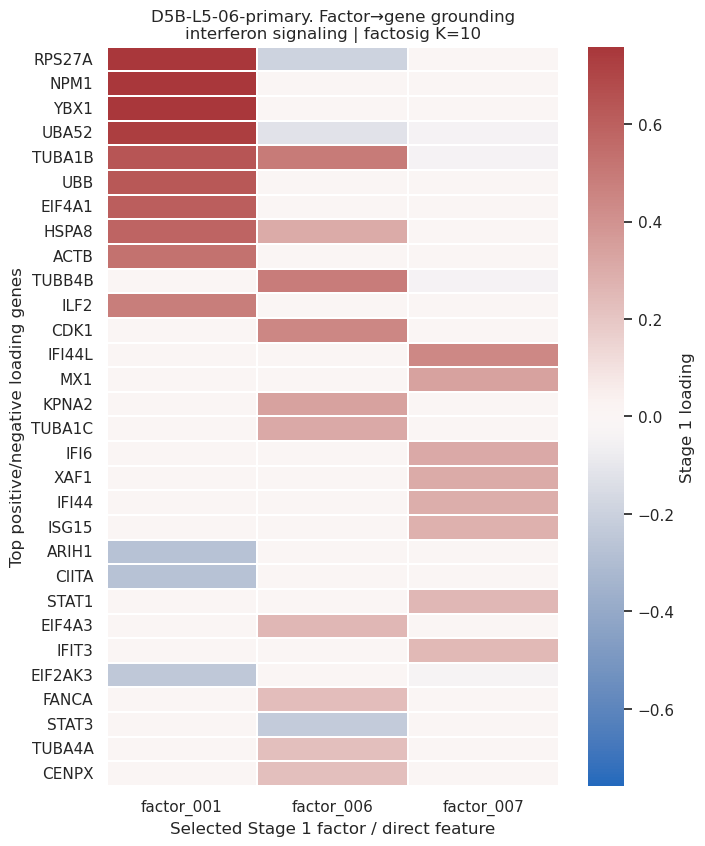

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D5B_L5-07-primary_hypoxia.png


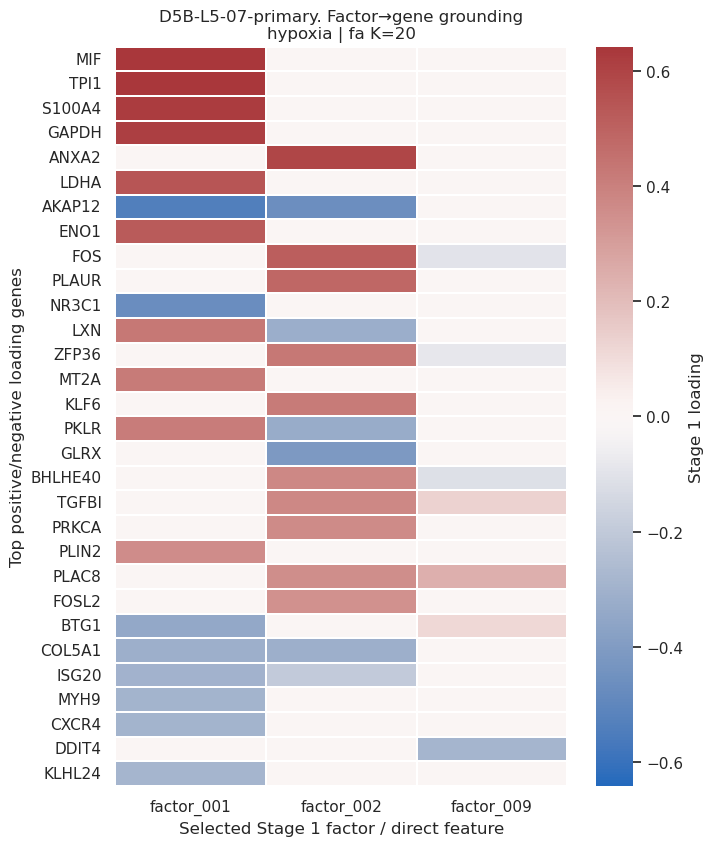

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D5B_L5-08-primary_interferon_gamma_signaling.png


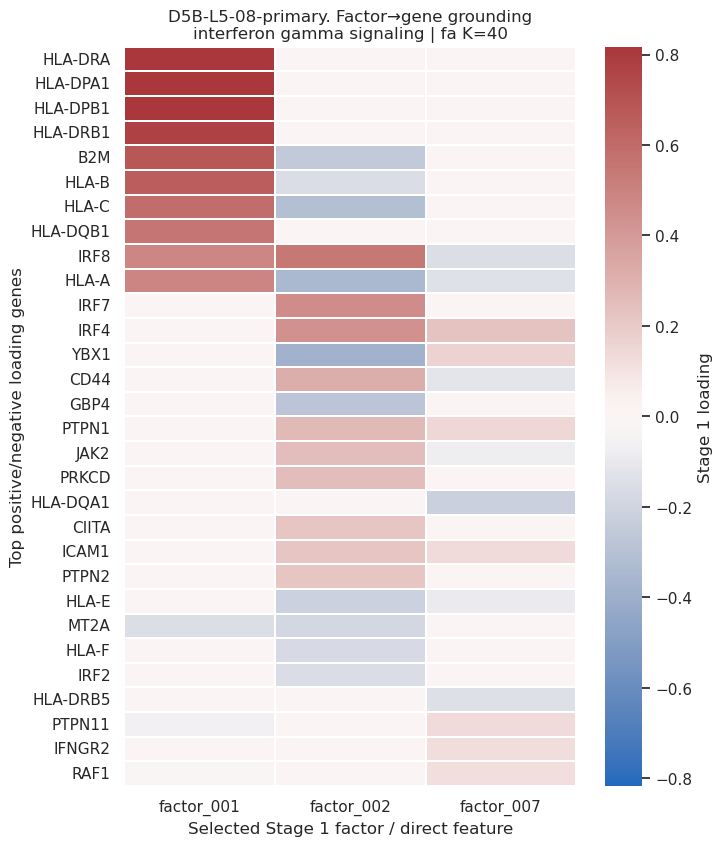

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D5B_L5-09-primary_unfolded_protein_response.png


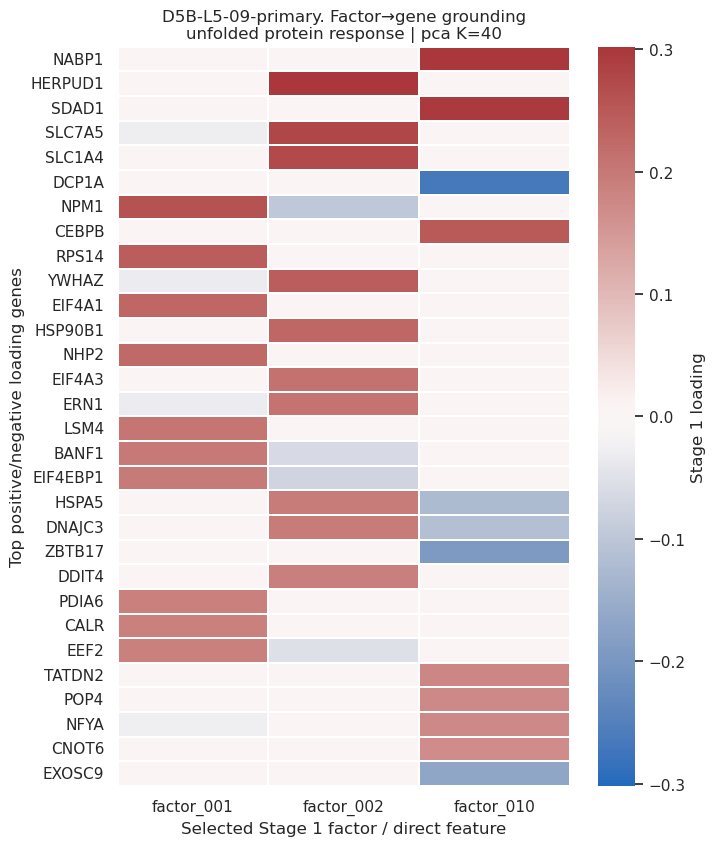

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D5B_L5-10-primary_tgf_beta_signaling.png


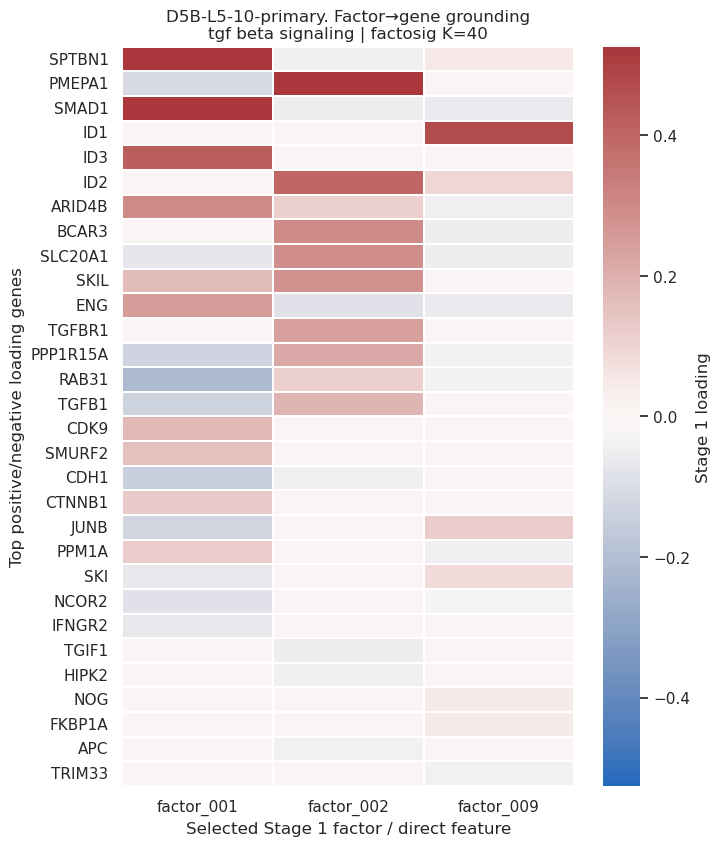

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D5B_L5-11-primary_antigen_processing_and_presentation.png


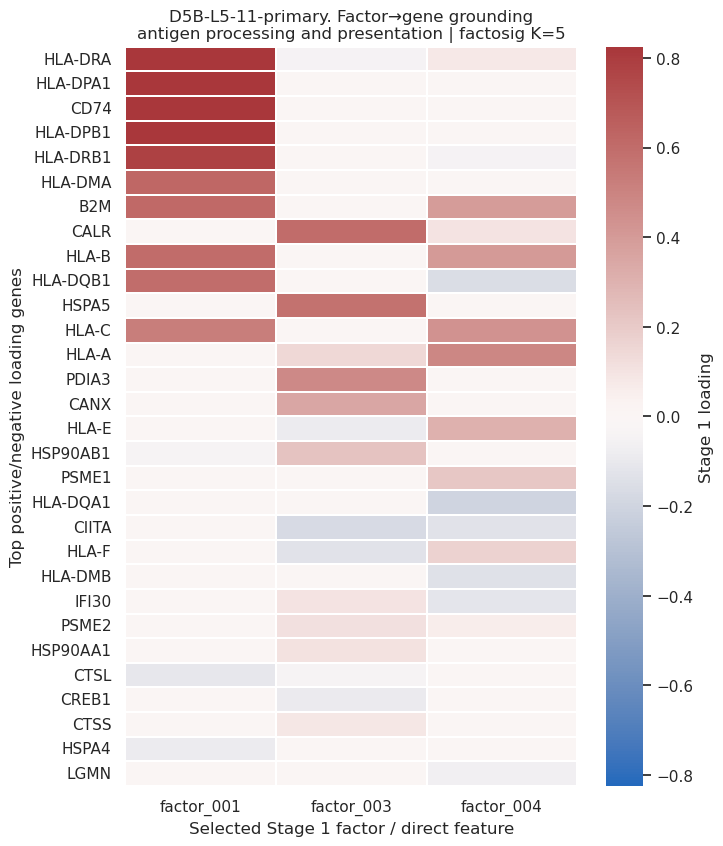

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D5B_L5-12-primary_proliferation_metabolism.png


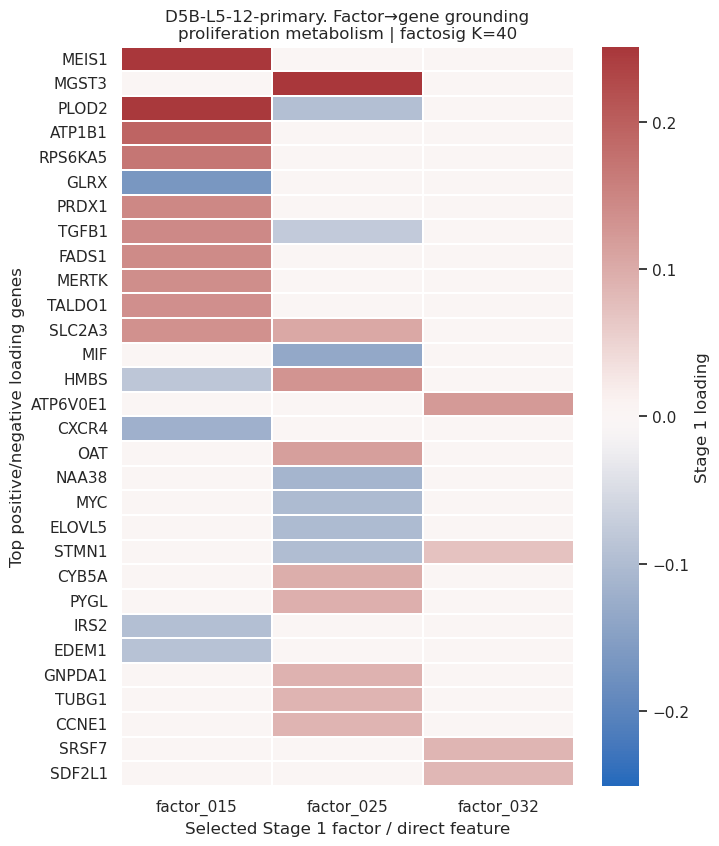

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D5B_L5-13-direct-gene_nf_kb_activation.png


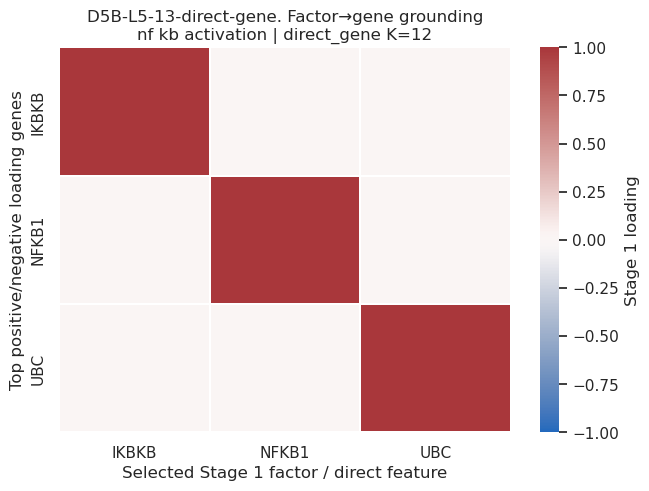

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D5B_L5-13-primary_nf_kb_activation.png


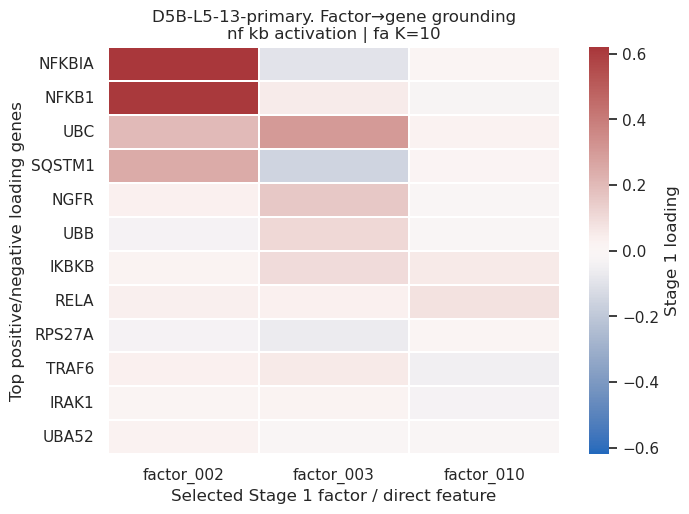

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D5B_L5-14-primary_p53_pathway.png


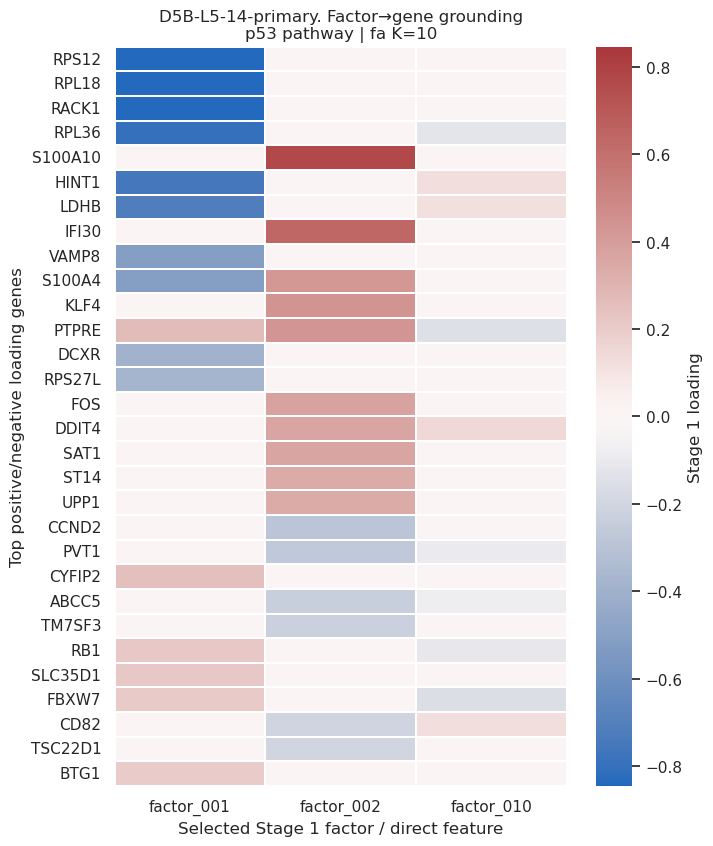

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D5C_patient_factor_overlap.png


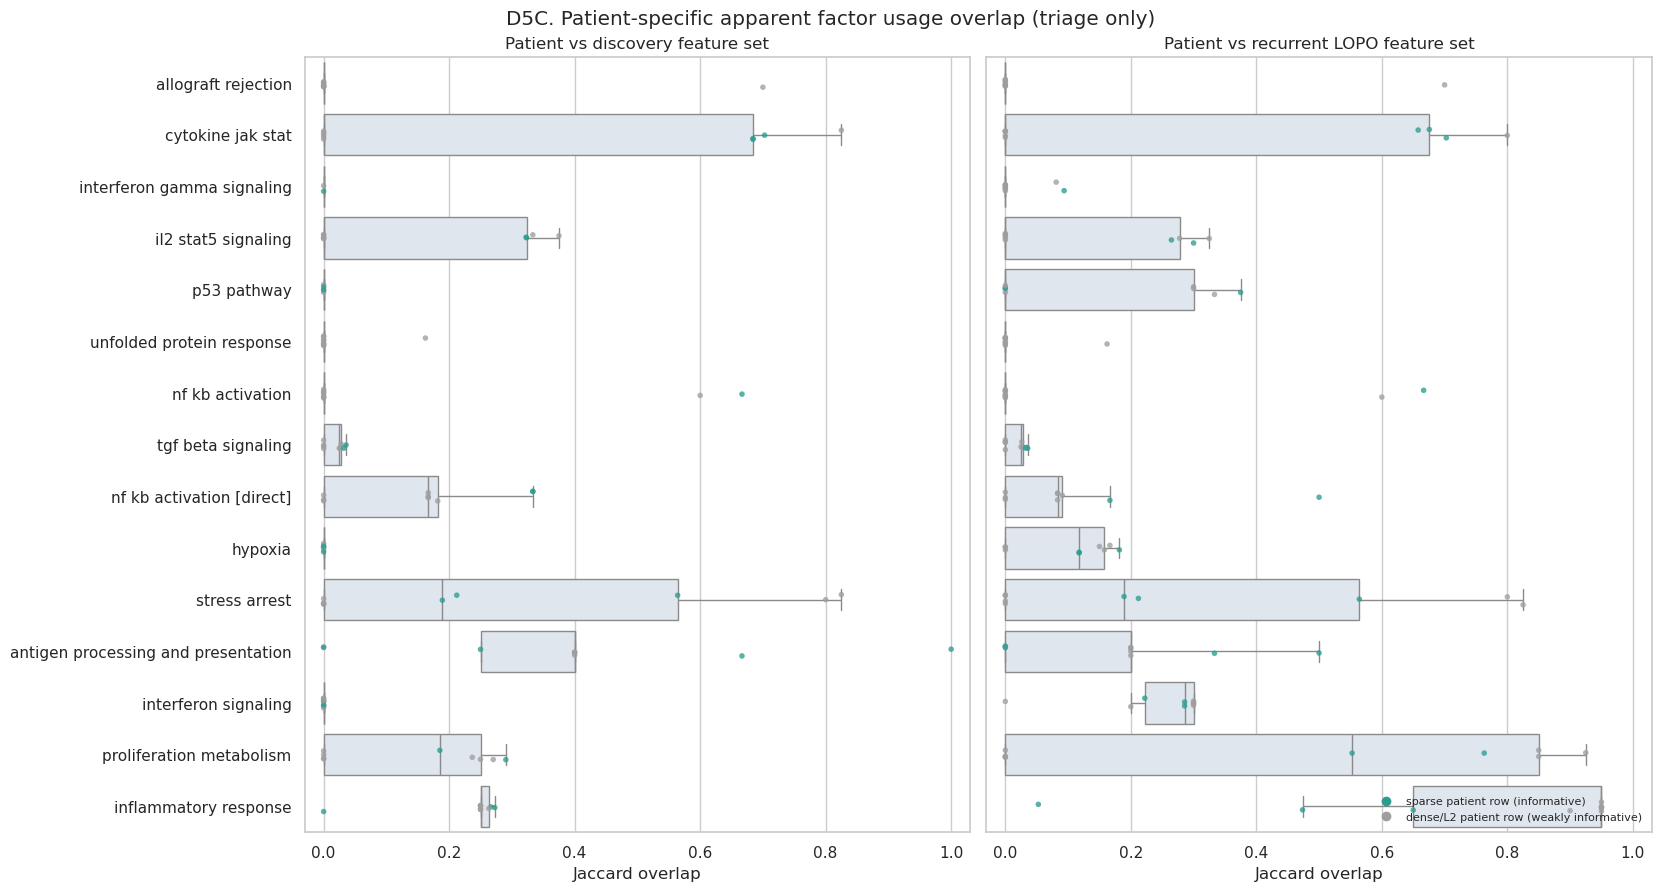

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/layer4_5/D5D_loading_concentration.png


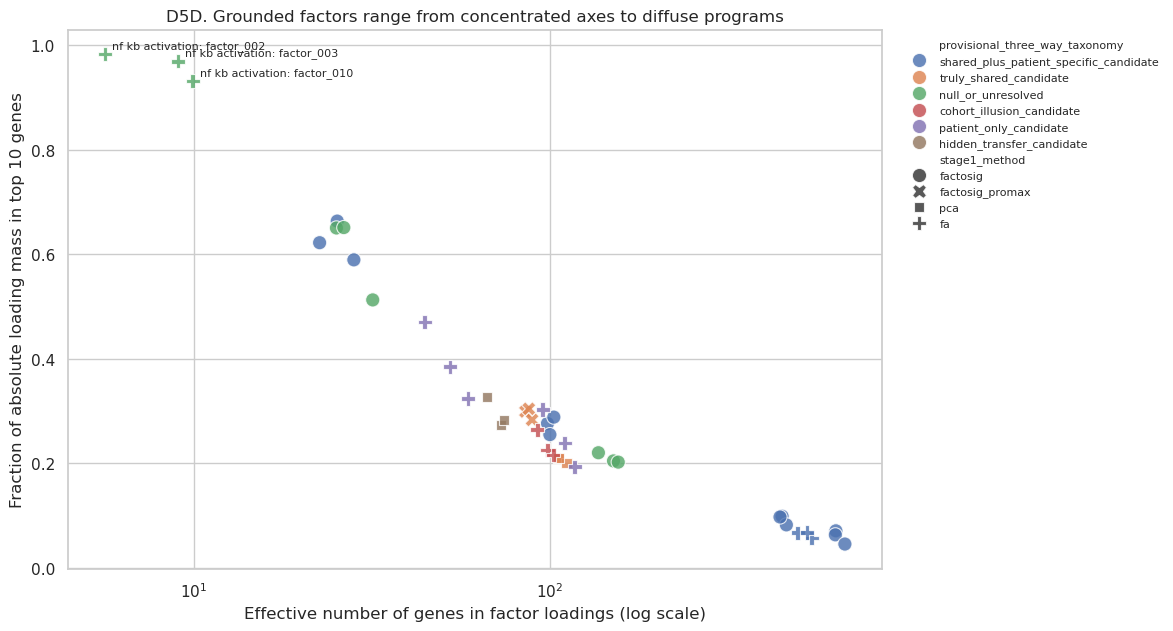

Generated 15 D5B factor→gene heatmaps.


In [7]:
# D5A — available recurrent factor depth plus the capped review subset.
d5a_grounded = (
    panel_selected_factors.groupby(
        [
            "grounding_target_id",
            "sample_order",
            "short_panel_label",
            "grounding_role",
            "provisional_three_way_taxonomy",
            "effective_k",
        ],
        as_index=False,
    )
    .agg(
        grounded_factor_count=("feature_id", "nunique"),
        fold_stable_grounded_factor_count=("lopo_fold_stable_feature", "sum"),
        median_lopo_selection_frequency=("lopo_selection_frequency", "median"),
    )
)
d5a_available = (
    layer5_lopo_feature_stability.groupby("grounding_target_id", as_index=False)
    .agg(
        factors_available_at_grounding_row=("feature_id", "nunique"),
        fold_stable_factors_available=("fold_stable_feature", "sum"),
        factors_selected_in_any_fold=("n_folds_selected", lambda values: int(pd.Series(values).gt(0).sum())),
    )
)
d5a = (
    d5a_grounded.merge(d5a_available, on="grounding_target_id", how="left", validate="one_to_one")
    .sort_values(["sample_order", "grounding_role"])
)
d5a["target_label"] = d5a["short_panel_label"] + np.where(
    d5a["grounding_role"].eq("legacy_direct_gene_sensitivity"), " [direct]", ""
)
fig, ax = plt.subplots(figsize=(10.8, 7.8))
y = np.arange(len(d5a))
ax.barh(
    y,
    d5a["factors_selected_in_any_fold"],
    color="#D8E2EE",
    label="selected in ≥1 LOPO fold",
)
ax.barh(
    y,
    d5a["fold_stable_factors_available"],
    color="#2A9D8F",
    label="fold-stable factors available",
)
ax.scatter(
    d5a["grounded_factor_count"],
    y,
    marker="D",
    s=45,
    color="#8C2D04",
    zorder=3,
    label="grounded review subset (cap = 3)",
)
ax.set_yticks(y, d5a["target_label"])
ax.invert_yaxis()
ax.set_xlabel("Factor/feature count at grounding regularization")
ax.set_ylabel("")
ax.set_title("D5A. Available fold-stable factors and the capped grounding review subset")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="x", alpha=0.2)
d5a_png = save_figure(fig, "D5A_grounded_factor_depth")
plt.show()

# D5B — one Stage 1 loading heatmap per grounding target.
d5b_pngs: list[Path] = []
for target_id, genes_long in panel_top_loading_genes.groupby("grounding_target_id", sort=True):
    target_context = layer5_targets.loc[layer5_targets["grounding_target_id"].eq(target_id)].iloc[0]
    matrix = genes_long.pivot_table(
        index="gene",
        columns="feature_id",
        values="loading",
        aggfunc="mean",
    ).fillna(0.0)
    row_score = matrix.abs().max(axis=1)
    matrix = matrix.loc[row_score.nlargest(min(30, len(row_score))).index]
    vmax = max(float(np.nanpercentile(np.abs(matrix.to_numpy()), 98)), 1e-9)
    fig, ax = plt.subplots(
        figsize=(max(6.8, 1.1 * matrix.shape[1] + 4), max(5.0, 0.24 * matrix.shape[0] + 2.4))
    )
    sns.heatmap(
        matrix,
        cmap="vlag",
        center=0,
        vmin=-vmax,
        vmax=vmax,
        linewidths=0.25,
        linecolor="white",
        cbar_kws={"label": "Stage 1 loading"},
        ax=ax,
    )
    ax.set_xlabel("Selected Stage 1 factor / direct feature")
    ax.set_ylabel("Top positive/negative loading genes")
    ax.set_title(
        f"D5B-{target_id}. Factor→gene grounding\n"
        f"{target_context['short_panel_label']} | {target_context['stage1_method']} K={int(target_context['effective_k'])}"
    )
    stem = re.sub(r"[^A-Za-z0-9_-]+", "_", f"D5B_{target_id}_{target_context['short_panel_label']}")
    d5b_pngs.append(save_figure(fig, stem))
    plt.show()

# D5C — patient-specific apparent feature-set overlap.
d5c = patient_factor_overlap.copy()
d5c["target_label"] = d5c["short_panel_label"] + np.where(
    d5c["grounding_target_id"].eq("L5-13-direct-gene"), " [direct]", ""
)
order = (
    d5c.groupby("target_label")["jaccard_patient_vs_lopo_recurrent"]
    .median()
    .sort_values()
    .index
)
fig, axes = plt.subplots(1, 2, figsize=(16.5, 8.8), sharey=True, constrained_layout=True)
for ax, metric, title in [
    (axes[0], "jaccard_patient_vs_discovery", "Patient vs discovery feature set"),
    (axes[1], "jaccard_patient_vs_lopo_recurrent", "Patient vs recurrent LOPO feature set"),
]:
    sns.boxplot(data=d5c, y="target_label", x=metric, order=order, color="#DCE6F1", fliersize=0, ax=ax)
    sns.stripplot(
        data=d5c,
        y="target_label",
        x=metric,
        order=order,
        hue="patient_overlap_informative",
        palette={True: "#2A9D8F", False: "#9E9E9E"},
        dodge=False,
        size=4,
        alpha=0.78,
        ax=ax,
    )
    ax.set_xlim(-0.03, 1.03)
    ax.set_xlabel("Jaccard overlap")
    ax.set_ylabel("")
    ax.set_title(title)
    if ax.legend_ is not None:
        ax.legend_.remove()
handles = [
    plt.Line2D([], [], marker="o", linestyle="", color="#2A9D8F", label="sparse patient row (informative)"),
    plt.Line2D([], [], marker="o", linestyle="", color="#9E9E9E", label="dense/L2 patient row (weakly informative)"),
]
axes[1].legend(handles=handles, loc="lower right", frameon=False, fontsize=8)
fig.suptitle("D5C. Patient-specific apparent factor usage overlap (triage only)")
d5c_png = save_figure(fig, "D5C_patient_factor_overlap")
plt.show()

# D5D — factor loading concentration.
d5d = panel_selected_factors.loc[
    panel_selected_factors["representation_family"].ne("direct_gene")
].copy()
fig, ax = plt.subplots(figsize=(10.5, 7.0))
sns.scatterplot(
    data=d5d,
    x="loading_effective_gene_number",
    y="loading_top10_absolute_mass",
    hue="provisional_three_way_taxonomy",
    style="stage1_method",
    s=105,
    alpha=0.82,
    ax=ax,
)
for _, row in d5d.nlargest(3, "loading_top10_absolute_mass").iterrows():
    ax.annotate(
        f"{row['short_panel_label']}: {row['feature_id']}",
        (row["loading_effective_gene_number"], row["loading_top10_absolute_mass"]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8,
    )
ax.set_xscale("log")
ax.set_xlabel("Effective number of genes in factor loadings (log scale)")
ax.set_ylabel("Fraction of absolute loading mass in top 10 genes")
ax.set_title("D5D. Grounded factors range from concentrated axes to diffuse programs")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=False, fontsize=8)
d5d_png = save_figure(fig, "D5D_loading_concentration")
plt.show()

print(f"Generated {len(d5b_pngs)} D5B factor→gene heatmaps.")

## 7. Integrated handoff, Section-10 contracts, and validation

The original 41-row table is not overwritten. The enriched table records Layer 4 flags for both primary pooled-LOPO and best-floor-oracle representations, panel-wide flag composition, and Layer 5 completion/sample summaries. A complete artifact ledger includes tables, figures, and reusable coefficient caches.

In [8]:
layer5_primary_factor_summary = (
    panel_selected_factors.loc[
        panel_selected_factors["grounding_role"].ne("legacy_direct_gene_sensitivity")
    ]
    .groupby("stage0_panel_id", as_index=False)
    .agg(
        layer5_n_grounded_factors=("feature_id", "nunique"),
        layer5_n_fold_stable_grounded_factors=("lopo_fold_stable_feature", "sum"),
        layer5_median_factor_selection_frequency=("lopo_selection_frequency", "median"),
        layer5_median_loading_effective_gene_number=("loading_effective_gene_number", "median"),
        layer5_median_loading_top10_mass=("loading_top10_absolute_mass", "median"),
    )
)
layer5_target_count = (
    layer5_targets.groupby("stage0_panel_id")["grounding_target_id"]
    .nunique()
    .rename("layer5_n_grounding_targets")
    .reset_index()
)

panel_enriched = panel.drop(columns=["interpretability_flag", "factor_gene_grounding_status"], errors="ignore").copy()
layer4_append_columns = [
    column
    for column in panel_coefficient_stability.columns
    if column == "stage0_panel_id" or column not in panel_enriched.columns
]
panel_enriched = panel_enriched.merge(
    panel_coefficient_stability[layer4_append_columns],
    on="stage0_panel_id",
    how="left",
    validate="one_to_one",
)
panel_enriched = panel_enriched.merge(
    layer5_primary_factor_summary,
    on="stage0_panel_id",
    how="left",
    validate="one_to_one",
).merge(
    layer5_target_count,
    on="stage0_panel_id",
    how="left",
    validate="one_to_one",
)
panel_enriched["factor_gene_grounding_status"] = np.where(
    panel_enriched["stage0_panel_id"].isin(set(layer5_panel_sample["stage0_panel_id"])),
    "completed_layer5_stratified_sample",
    "not_sampled_layer5",
)
panel_enriched["layer5_n_grounding_targets"] = panel_enriched["layer5_n_grounding_targets"].fillna(0).astype(int)
panel_enriched["layer4_5_suite_version"] = "old34_layer4_5_v1"
panel_enriched["layer4_5_is_inferential"] = False
panel_enriched = panel_enriched.sort_values("robust_q1_rank").reset_index(drop=True)
enriched_panel_path = write_csv(
    panel_enriched,
    "old34_panel_diagnostic_table_layer4_5.csv",
)

layer4_counts = representation_interpretability["interpretability_flag"].value_counts().to_dict()
panel_layer4_counts = panel_enriched["interpretability_flag"].value_counts().to_dict()
layer5_taxonomy_counts = layer5_panel_sample["provisional_three_way_taxonomy"].value_counts().to_dict()

plot_contracts = pd.DataFrame(
    [
        {
            "plot_id": "D4A",
            "title": "Dense-solution prevalence by selection view",
            "scientific_question": "Do performance selection rules predominantly choose dense kitchen-sink probes?",
            "null_hypothesis": "Path maxima and performance-selected rows are not predominantly dense (>80% of available features).",
            "in_silico_experiment": "Compare discovery-path maximum, pooled-LOPO-selected discovery row, LOPO-path maximum, and pooled-LOPO-selected LOPO row across all 643 representations.",
            "unit_of_analysis": "representation",
            "metric_and_baseline": "nonzero coefficient fraction; dense threshold 0.80",
            "result_summary": json.dumps(dict(zip(d4a["selection_view"], d4a["dense_representations"])), sort_keys=True),
            "take_home_message": "Dense selection frequency is an interpretability warning, not a performance failure.",
            "unresolved_gaps": "Threshold is descriptive; no external biological validation or second Stage 1 seed.",
        },
        {
            "plot_id": "D4B",
            "title": "LOPO sparsity versus transfer floor",
            "scientific_question": "Does lower-tail transfer coincide with sparse, fold-stable factor usage?",
            "null_hypothesis": "Positive p20 transfer is unrelated to coefficient density/stability.",
            "in_silico_experiment": "Plot all 643 pooled-LOPO-selected rows by mean LOPO nonzero fraction and p20 held-out lift; color by Layer 4 flag.",
            "unit_of_analysis": "representation",
            "metric_and_baseline": "nonzero fraction versus p20 AUPRC lift; zero lift is patient prevalence",
            "result_summary": json.dumps(layer4_counts, sort_keys=True),
            "take_home_message": "Performance and factor interpretability must be gated separately.",
            "unresolved_gaps": "LOPO uses a transductive Stage 1 basis and one Stage 1 seed.",
        },
        {
            "plot_id": "D4C",
            "title": "Near-best sparse trade-off",
            "scientific_question": "Can dense discovery maxima be replaced by much sparser rows with little apparent AUPRC loss?",
            "null_hypothesis": "No sparse L1/elastic-net row lies within 0.02 AUPRC of a dense discovery maximum.",
            "in_silico_experiment": "For every dense discovery path maximum, search the same 65-setting path for a nonzero fraction <=0.50 row within ΔAUPRC 0.02.",
            "unit_of_analysis": "dense-max representation with available sparse alternative",
            "metric_and_baseline": "apparent discovery AUPRC drop versus reduction in nonzero fraction",
            "result_summary": f"{len(d4c)} dense maxima have a near-best sparse alternative; median AUPRC drop {d4c['discovery_near_best_sparse_auprc_drop'].median():.4f}.",
            "take_home_message": "Factor-level interpretation can often use a sparse sensitivity row without claiming it is independently validated.",
            "unresolved_gaps": "Discovery metric is in-sample and the 0.02 tolerance is pre-specified triage, not inference.",
        },
        {
            "plot_id": "D4D",
            "title": "Panel interpretability composition",
            "scientific_question": "Are interpretability problems isolated to one representation or pervasive within a Stage 0 gene space?",
            "null_hypothesis": "Panels do not differ in sparse/dense/unstable representation composition.",
            "in_silico_experiment": "Count Layer 4 flags across every observed method/K representation within each of 41 panels.",
            "unit_of_analysis": "panel x representation flag",
            "metric_and_baseline": "counts of sparse, dense, and unstable representations",
            "result_summary": json.dumps(panel_layer4_counts, sort_keys=True),
            "take_home_message": "Panel-wide composition distinguishes a brittle representation from a broadly uninterpretable gene space.",
            "unresolved_gaps": "Single Stage 1 seed prevents seed-stability assessment.",
        },
        {
            "plot_id": "D4E",
            "title": "LOPO coefficient stability heatmaps",
            "scientific_question": "Which selected factors recur with consistent sign when each patient is held out?",
            "null_hypothesis": "Selected factor coefficients are stable across all held-out-patient folds.",
            "in_silico_experiment": "At each of 15 grounding targets and its fixed grounding regularization, plot the top coefficient factors across 13 LOPO folds.",
            "unit_of_analysis": "factor x held-out patient within one representation",
            "metric_and_baseline": "signed Stage 2 coefficient; zero means unselected",
            "result_summary": f"{len(d4e_pngs)} target heatmaps generated.",
            "take_home_message": "Only recurrent, sign-consistent factors support a shared factor-level biology claim.",
            "unresolved_gaps": "Factor coefficients are conditional on one transductive Stage 1 basis.",
        },
        {
            "plot_id": "D5A",
            "title": "Grounded factor depth",
            "scientific_question": "Does each sampled panel contribute one axis or several recurrent axes?",
            "null_hypothesis": "Each prior panel behaves as one undifferentiated axis.",
            "in_silico_experiment": "Count factors selected in any LOPO fold and fold-stable factors at each grounding row; overlay the capped three-factor review subset for 15 stratified targets.",
            "unit_of_analysis": "grounding target",
            "metric_and_baseline": "available any-fold/stable factor count and grounded review-subset count",
            "result_summary": f"{panel_selected_factors['feature_id'].nunique()} factor labels across {panel_selected_factors['grounding_target_id'].nunique()} within-target bases (factor IDs are not cross-target identities).",
            "take_home_message": "Available recurrent factor depth can exceed the capped review subset and motivates sub-axis biological review within a panel.",
            "unresolved_gaps": "The cap of three factors is a review budget, not an estimate of true dimensionality.",
        },
        {
            "plot_id": "D5B",
            "title": "Factor-to-gene loading heatmaps",
            "scientific_question": "Which positive and negative genes define each selected latent factor?",
            "null_hypothesis": "Selected factors lack concentrated, distinguishable gene-loading structure.",
            "in_silico_experiment": "Map factor IDs to Stage 1 loading columns and extract ten positive plus ten negative genes per factor; direct-gene target uses identity mapping.",
            "unit_of_analysis": "gene x factor within one representation",
            "metric_and_baseline": "signed Stage 1 loading; zero is no loading contribution",
            "result_summary": f"{len(panel_top_loading_genes)} factor→gene rows across {len(d5b_pngs)} target heatmaps.",
            "take_home_message": "Gene loadings provide names and opposing poles for Stage 2-selected axes.",
            "unresolved_gaps": "Loadings are single-seed and do not establish causal or biomarker status.",
        },
        {
            "plot_id": "D5C",
            "title": "Patient factor overlap",
            "scientific_question": "Do patients use the same factors as discovery and recurrent LOPO models?",
            "null_hypothesis": "Patient-specific selected factor sets are identical to shared/discovery sets.",
            "in_silico_experiment": "Compare each apparent patient-specific best-row feature set with same-regularization discovery and recurrent LOPO sets.",
            "unit_of_analysis": "patient x grounding target",
            "metric_and_baseline": "Jaccard overlap from 0 (disjoint) to 1 (identical)",
            "result_summary": f"{len(patient_factor_overlap)} patient-target comparisons; {int(patient_factor_overlap['patient_overlap_informative'].sum())} use sparse, informative patient rows.",
            "take_home_message": "Low sparse-row overlap nominates heterogeneous factor usage; dense/L2 overlaps are visually de-emphasized.",
            "unresolved_gaps": "Patient-specific rows are apparent/in-sample and should not be read as validated personalization.",
        },
        {
            "plot_id": "D5D",
            "title": "Factor loading concentration",
            "scientific_question": "Are selected factors concentrated gene axes or diffuse programs?",
            "null_hypothesis": "Selected factors have equivalent loading concentration.",
            "in_silico_experiment": "Compute entropy-derived effective gene count and top-10 absolute loading mass for every grounded DR factor.",
            "unit_of_analysis": "selected factor within one representation",
            "metric_and_baseline": "effective gene count versus top-10 loading mass",
            "result_summary": f"{len(d5d)} DR factors characterized.",
            "take_home_message": "Concentrated factors are easier to name; diffuse factors require program-level interpretation.",
            "unresolved_gaps": "Loading scale and rotation differ by Stage 1 method, so comparisons are descriptive.",
        },
    ]
)
plot_contracts_path = write_csv(plot_contracts, "layer4_5_plot_contracts.csv")

report_lines = [
    "# Old34 Layer 4–5 grounding report",
    "",
    f"Generated: {datetime.now(timezone.utc).isoformat()}",
    "",
    "## Layer 4 summary",
    "",
    f"- Representation flags: `{json.dumps(layer4_counts, sort_keys=True)}`.",
    f"- Primary pooled-LOPO panel flags: `{json.dumps(panel_layer4_counts, sort_keys=True)}`.",
    f"- Dense discovery maxima with near-best sparse alternatives: {len(d4c)}.",
    f"- Median discovery AUPRC drop for those alternatives: {d4c['discovery_near_best_sparse_auprc_drop'].median():.4f}.",
    "",
    "## Layer 5 sample",
    "",
    f"- 14 unique panels and 15 grounding targets.",
    f"- Taxonomy coverage: `{json.dumps(layer5_taxonomy_counts, sort_keys=True)}`.",
    f"- Grounded factors/features: {len(panel_selected_factors)}.",
    f"- Factor→gene rows: {len(panel_top_loading_genes)}.",
    f"- Patient-target overlap rows: {len(patient_factor_overlap)}.",
    "",
    "## Interpretation guardrails",
    "",
    "- Layer 4 thresholds are descriptive and versioned, not p-values.",
    "- Stage 1 is transductive and uses one seed (42).",
    "- Factor IDs are comparable only within a fixed representation.",
    "- Patient-specific rows are apparent fits trained and scored on the same patient cells.",
    "- Coefficients select factors; Stage 1 loadings, not coefficients alone, define genes.",
    "- Direct-gene NF-kB is an identity sensitivity, not a latent decomposition.",
]
report_path = TABLE_DIR / "layer4_5_factor_gene_grounding_report.md"
report_path.write_text("\n".join(report_lines) + "\n")

manifest = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "experiment_id": EXPERIMENT_ID,
    "suite_version": "old34_layer4_5_v1",
    "thresholds": {
        "dense_nonzero_fraction": DENSE_THRESHOLD,
        "sparse_nonzero_fraction": SPARSE_THRESHOLD,
        "near_best_auprc_tolerance": NEAR_BEST_TOLERANCE,
        "fold_stable_selection_frequency": STABLE_SELECTION_FREQUENCY,
        "fold_stable_sign_stability": STABLE_SIGN_THRESHOLD,
        "unstable_pairwise_support_jaccard": UNSTABLE_JACCARD_THRESHOLD,
    },
    "counts": {
        "representations": len(representation_interpretability),
        "panels": len(panel_enriched),
        "layer5_sample_panels": layer5_panel_sample["stage0_panel_id"].nunique(),
        "layer5_grounding_targets": layer5_targets["grounding_target_id"].nunique(),
        "grounded_factors": len(panel_selected_factors),
        "factor_gene_rows": len(panel_top_loading_genes),
        "patient_overlap_rows": len(patient_factor_overlap),
    },
    "source_files": {name: source_signature(path) for name, path in SOURCE_PATHS.items()},
    "coefficient_cache_note": "Caches are invalidated by source size/mtime plus exact wanted-selection hash.",
}
manifest_path = TABLE_DIR / "layer4_5_manifest.json"
manifest_path.write_text(json.dumps(manifest, indent=2) + "\n")

# Comprehensive ledger; exclude ledger/validation themselves to avoid recursive hashes.
ledger_path = TABLE_DIR / "layer4_5_generated_artifact_ledger.csv"
validation_path = TABLE_DIR / "layer4_5_validation.json"
artifact_paths = sorted(
    {
        path
        for root in [TABLE_DIR, FIGURE_DIR, CACHE_DIR]
        for path in root.rglob("*")
        if path.is_file() and path not in {ledger_path, validation_path}
    }
)
ledger_records = []
for path in artifact_paths:
    if path.suffix.lower() == ".csv":
        artifact_type = "table"
        n_rows = len(pd.read_csv(path, low_memory=False))
    elif path.suffix.lower() in {".png", ".pdf"}:
        artifact_type = "figure"
        n_rows = np.nan
    elif path.suffix.lower() == ".md":
        artifact_type = "report"
        n_rows = np.nan
    elif path.suffix.lower() == ".json":
        artifact_type = "manifest_or_cache_metadata"
        n_rows = np.nan
    elif ".pkl" in path.name:
        artifact_type = "coefficient_cache"
        n_rows = np.nan
    else:
        artifact_type = "other"
        n_rows = np.nan
    ledger_records.append(
        {
            "artifact_id": path.stem,
            "artifact_type": artifact_type,
            "relative_path": str(path.relative_to(EXP_DIR)),
            "size_bytes": path.stat().st_size,
            "sha256": sha256_file(path),
            "n_rows_if_csv": n_rows,
            "modified_utc": datetime.fromtimestamp(path.stat().st_mtime, timezone.utc).isoformat(),
        }
    )
artifact_ledger = pd.DataFrame(ledger_records).sort_values(["artifact_type", "relative_path"]).reset_index(drop=True)
artifact_ledger.to_csv(ledger_path, index=False)

assert len(representation_interpretability) == 643
assert representation_interpretability["representation_id"].nunique() == 643
assert len(panel_coefficient_stability) == 41
assert len(panel_enriched) == 41
assert panel_enriched["stage0_panel_id"].nunique() == 41
assert panel_enriched["interpretability_flag"].notna().all()
assert panel_enriched["factor_gene_grounding_status"].eq("completed_layer5_stratified_sample").sum() == 14
assert layer5_targets["grounding_target_id"].nunique() == 15
assert layer5_lopo_feature_stability["grounding_target_id"].nunique() == 15
assert panel_selected_factors["grounding_target_id"].nunique() == 15
assert panel_top_loading_genes["grounding_target_id"].nunique() == 15
assert patient_factor_overlap["grounding_target_id"].nunique() == 15
assert len(d4e_pngs) == 15
assert len(d5b_pngs) == 15
for path in artifact_paths + [ledger_path]:
    assert path.exists() and path.stat().st_size > 0, path

disk = shutil.disk_usage(EXP_DIR)
free_gib = disk.free / 1024**3
used_fraction = disk.used / disk.total
validation = {
    "validated_utc": datetime.now(timezone.utc).isoformat(),
    "status": "pass",
    "representation_rows": len(representation_interpretability),
    "panel_rows": len(panel_enriched),
    "layer5_sample_panels": layer5_panel_sample["stage0_panel_id"].nunique(),
    "layer5_grounding_targets": layer5_targets["grounding_target_id"].nunique(),
    "grounded_factor_rows": len(panel_selected_factors),
    "factor_gene_rows": len(panel_top_loading_genes),
    "patient_overlap_rows": len(patient_factor_overlap),
    "plot_contract_rows": len(plot_contracts),
    "tracked_artifacts_excluding_ledger_and_validation": len(artifact_ledger),
    "tracked_bytes_excluding_ledger_and_validation": int(artifact_ledger["size_bytes"].sum()),
    "filesystem_free_gib": free_gib,
    "filesystem_used_fraction": used_fraction,
    "heavy_run_allowed": bool(free_gib >= 50 and used_fraction <= 0.90),
    "notes": [
        "No Stage 0, Stage 1, or Stage 2 model was rerun.",
        "Coefficient caches are derived and signature-checked.",
        "Ledger and validation exclude themselves from checksum accounting.",
    ],
}
validation_path.write_text(json.dumps(validation, indent=2) + "\n")
assert validation_path.stat().st_size > 0

print("Validation: PASS")
print("Layer 4 representation flags:", layer4_counts)
print("Layer 4 primary panel flags:", panel_layer4_counts)
print("Layer 5 taxonomy coverage:", layer5_taxonomy_counts)
print(f"Tracked artifacts: {len(artifact_ledger) + 2} including ledger + validation")
print(f"Tracked size: {(artifact_ledger['size_bytes'].sum() + ledger_path.stat().st_size + validation_path.stat().st_size) / 1024**2:.1f} MiB")
print(f"Filesystem free: {free_gib:.1f} GiB ({used_fraction:.1%} used)")
display(panel_enriched[["robust_q1_rank", "short_panel_label", "interpretability_flag", "factor_gene_grounding_status"]].head(20))

Validation: PASS
Layer 4 representation flags: {'dense': 368, 'sparse': 174, 'unstable': 101}
Layer 4 primary panel flags: {'sparse': 18, 'dense': 14, 'unstable': 9}
Layer 5 taxonomy coverage: {'shared_plus_patient_specific_candidate': 5, 'null_or_unresolved': 3, 'truly_shared_candidate': 2, 'patient_only_candidate': 2, 'cohort_illusion_candidate': 1, 'hidden_transfer_candidate': 1}
Tracked artifacts: 94 including ledger + validation
Tracked size: 10.6 MiB
Filesystem free: 472.0 GiB (41.0% used)


,robust_q1_rank,short_panel_label,interpretability_flag,factor_gene_grounding_status
0,1,stress arrest,sparse,completed_layer5_stratified_sample
1,2,cytokine jak stat,dense,completed_layer5_stratified_sample
2,3,inflammatory response,dense,completed_layer5_stratified_sample
3,4,cytokine signaling in immune system,dense,not_sampled_layer5
4,5,allograft rejection,sparse,completed_layer5_stratified_sample
5,6,apoptosis,dense,not_sampled_layer5
6,7,inflammatory interferon,sparse,not_sampled_layer5
7,8,tgf plasticity,sparse,not_sampled_layer5
8,9,interferon signaling,unstable,completed_layer5_stratified_sample
9,10,innate immune context,sparse,not_sampled_layer5


## 8. Review gates after Layer 4–5

### Ready for human review

1. D4A–D4D: decide whether the sparse/dense/unstable definitions communicate the interpretability gate clearly.
2. D4E: inspect fold recurrence before accepting any factor-level claim.
3. D5B: name factors from both positive and negative gene poles; do not name from one top gene.
4. D5C: prioritize sparse patient rows; gray dense/L2 points are weakly informative.
5. D5D: distinguish concentrated candidate axes from diffuse program-level factors.

### Canonical enriched deliverables

- `representation_interpretability_flags.csv` — all 643 representations.
- `panel_coefficient_stability_summary.csv` — 41-panel Layer 4 roll-up.
- `old34_panel_diagnostic_table_layer4_5.csv` — enriched 41-row table; original is preserved.
- `layer5_panel_sample_manifest.csv` and `layer5_grounding_target_manifest.csv` — auditable sample/target choices.
- `panel_selected_factors_summary.csv`, `panel_top_loading_genes.csv`, and `patient_factor_overlap_vs_discovery.csv` — planned Layer 5 outputs.
- `layer4_5_plot_contracts.csv` — Section-10 framing for every D4/D5 plot family.
- `layer4_5_factor_gene_grounding_report.md`, manifest, validation, and artifact ledger.

### Still not evidence-complete

Matched-size gene controls, uncertainty intervals, a second Stage 1 seed, an inductive Stage 1 refit, and external biological validation remain open. Layer 4–5 closes the analytical implementation gap; it does not convert exploratory factors into confirmatory biomarkers.